# Task 13 — Customer value at a gift wholesaler: who to call before Christmas, and what to offer

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Online Retail II](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci) (every invoice line of a UK online giftware wholesaler, Dec 2009 – Dec 2011; UCI Machine Learning Repository, Chen 2019)
**Task family:** customer-level supervised learning, probabilistic customer-base models, recommendation with cold start, temporal validation · **Companion task:** `02_card_fraud_tabular.ipynb` (the same honest evaluation, with a quarterly call list in place of an alert queue)

---

## The task card

> **Board question.** *Our account managers can make about 200 calls a quarter, one for every 22 of the 4,324 trade customers who bought in the last twelve months. Before the Christmas season (September–November 2011), which 200 should they call — the biggest accounts or those going quiet — what should each call offer, and does a model beat the sales spreadsheet?*

**Business context.** A UK wholesaler sells giftware online to shops, and more than a third of its year falls in September–November, when they stock up for Christmas. The model joins a legacy estate: the web shop's orders (these invoice lines), finance's credit notes and write-offs, a free-text catalogue, and the account managers' spreadsheet sorted by last year's revenue. Two Session 01 patterns meet: an *offline batch* writing a quarterly call list into the CRM, and a *human in the loop* who calls and needs a recommendation (`GET /recommend/{customer}`).

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **customer-value model** (will this customer buy next quarter, and how much?), packaged and reproducible, evaluated *forward* into the Christmas quarter against the spreadsheet, RFM and BG/NBD, with the traps guarded by tests;
2. a **call list chosen from capacity and cost**, with the unmeasured value of a call made explicit in an ADR;
3. the given **recommender**, packaged and evaluated forward with hit-rate@10, new products included, and a **product taxonomy** knowledge base with its ablation;
4. the **operational wrapper**: package, CI gate on a frozen Christmas quarter, registry, model card, monitoring.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Quarterly batch into the CRM, recommendation during the call; GDPR for pseudonymous trade customers |
| 2 · MLOps | Rolling-origin panel, forward test on Christmas, gate on ranking, level and hit-rate |
| 3 · Semantic layer | Product taxonomy as SKOS with SHACL; the cold-start ablation |
| 4 · LLM/RAG | Account-manager brief from a context pack; description normalisation |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: one UK online retailer's invoice lines, donated to UCI with customer numbers instead of names. Missing: a record of calls, so what a call *changes* (its uplift) is an assumption throughout; and catalogue dates, so a product's first sale stands in for its launch.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at season, concentration and repeat buying | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | Features at the cut-off and the given models, the call list, the recommender and product taxonomy, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The range and the level after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the level swing and range turnover your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `pseudonym` and `load_lines` (Section 1); `customer_lines`, `customer_table`, `make_panel`, `bgnbd_inputs`, `bgnbd_fit`, `bgnbd_predict`, `gamma_gamma_fit`, `bgnbd_forecast`, `rfm_score`, `evaluate`, `fit_models`, `split` and `compare` (Section 3); `capture` and `list_stats` (Section 4); `norm_desc`, `build_taxonomy`, `rec_data`, `knn_scores`, `top_n`, `hit_rate`, `content`, `cold_start` and `context_pack` (Section 5); `psi_shares` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 24,824 customer-quarters from 7 cut-offs, 18 features; the test model trains on 20,500 and scores the 4,324-customer book on Sep–Nov 2011; LightGBM AUC 0.778 against the spreadsheet's 0.746; re-levelling by ×1.37 brings forecast ÷ realised to 0.98 (MAE £424); 102 save calls plus 98 grow calls; item-kNN hit-rate@10 41.1 % against popularity's 30.2 %.
- **Runtime:** about 1–2 minutes on a laptop (83 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, re, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc
import lightgbm as lgb
import sklearn
import scipy
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF
from rdflib.namespace import SKOS
from scipy import optimize, sparse, special
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*match groups.*")
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                   # threads per model; raise it on your own laptop
KAGGLE_HANDLE = "mashlyn/online-retail-ii-uci"
RAW_FILE = "online_retail_II.csv"
WINDOW_START, WINDOW_END = pd.Timestamp("2009-12-01"), pd.Timestamp("2011-12-10")   # all of it: 1.07 M invoice lines
CUTOFFS = pd.date_range("2010-03-01", "2011-09-01", freq="3MS")   # quarterly cut-offs; quarters run Dec–Feb, Mar–May, Jun–Aug, Sep–Nov
VALID_CUTOFF = pd.Timestamp("2011-06-01")    # target Jun–Aug 2011: settings are chosen here
TEST_CUTOFF = pd.Timestamp("2011-09-01")     # target Sep–Nov 2011, the Christmas buying season: the frozen holdout
HORIZON_MONTHS = 3                           # "next quarter"
ACTIVE_MONTHS = 12                           # the account book: customers with a purchase in the 12 months before the cut-off
CALLS_PER_QUARTER = 200                      # calls the account managers can make in a quarter (assumption — task C3)
CALL_COST_GBP = 40.0                         # one call with preparation and follow-up (assumption — task C3)
GROSS_MARGIN = 0.35                          # margin on a wholesale order (assumption — task C3)
WIN_BACK_RATE = 0.20                         # share of a lapsing customer's quarter a call wins back: NEVER measured here (assumption — task C3)
SILENT_DAYS = 60                             # the spreadsheet's "at risk" rule: a big account silent for this long
TOP_N = 10                                   # length of a recommendation list (hit-rate@10)
KNN_NEIGHBOURS = 50                          # neighbours kept per item in item-kNN
PSEUDONYM_KEY = b"ari3217-task13-demo-key"   # in production a secret from the vault, never in Git
NON_PRODUCT = {"POST", "DOT", "C2", "C3", "M", "m", "D", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK", "ADJUST",
               "ADJUST2", "PADS", "TEST001", "TEST002", "GIFT"}   # plus every gift_0001_* voucher (see the dataset card)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "online_retail_ii", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · scipy {scipy.__version__} · "
      f"numpy {np.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · scipy 1.18.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `pseudonym` and `load_lines`; the quirks become C1's tests.*

| Field | Value |
|---|---|
| **Source** | Kaggle `mashlyn/online-retail-ii-uci`: one CSV made from the UCI *Online Retail II* workbook (Chen, 2019) |
| **Licence** | Kaggle lists CC0; UCI distributes the original under CC BY 4.0 (check the UCI page; our reading: cite UCI and the donor) |
| **Provenance** | Real invoice lines of one UK online giftware retailer, mostly selling to businesses; no names |
| **Size** | 1,067,371 rows; 1,044,848 after removing a duplicated week (quirk 1); 53,628 invoices, 5,942 customers, 5,305 stock codes, 43 countries; 1 Dec 2009 – 9 Dec 2011 |
| **Files** | `online_retail_II.csv` (95 MB) |
| **Schema** | `Invoice` (a leading `C` marks a cancellation), `StockCode`, `Description` (free text), `Quantity`, `InvoiceDate`, `Price` (£ a unit), `Customer ID`, `Country` |
| **Label** | None supplied; we build *buys again* (any purchase next quarter) and *next-quarter net revenue* per customer |
| **Window used here** | All of it (≈ 90 MB in memory); seven quarterly cut-offs; choose on Jun–Aug 2011, report once on Sep–Nov 2011 |
| **PII** | No names, but a customer number identifies a business that may be a sole trader (personal data under GDPR, our reading), and adjustment notes name staff: keyed hashes and redaction on load |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **One week is in the file twice.** Both sheets of the UCI workbook contain 1–9 December 2010 and the CSV stacks them: 22,523 lines (1,088 invoices, £377,488) appear twice. The project card does not mention it (Trap 1).
2. ⚠ **Cancellations are separate invoices**: 19,165 lines on 8,292 `C` invoices take back £719,656 (3.7 % of gross product sales), including the two largest orders in the data (Trap 2).
3. ⚠ **22.5 % of lines have no customer**, 13.1 % of gross product sales (Trap 3).
4. ⚠ **27 stock codes are not products**: postage, carriage, manual adjustments, discounts, bank and Amazon fees, bad-debt write-offs (six `A` invoices), samples, vouchers, tests. 5,832 lines, net −£71,536 (Trap 4).
5. **Stock adjustments look like returns**: 3,391 negative-quantity lines without a `C`, all at price 0, none with a customer: warehouse notes.
6. **Free-text descriptions**: 646 of 4,895 product codes carry several wordings; 11,812 lines repeat exactly inside an invoice (kept: possibly two scans).

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def pseudonym(customer_id: float) -> str:
    """Keyed hash of the shop's customer number: stable across runs, not reversible without the key."""
    return "c" + hashlib.blake2b(str(int(customer_id)).encode(), key=PSEUDONYM_KEY, digest_size=4).hexdigest()

def load_lines() -> pd.DataFrame:
    cache = PROCESSED / "13_retail_lines.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    convert = pc.ConvertOptions(column_types={"Invoice": pa.string(), "StockCode": pa.string(), "Description": pa.string(),
                                              "Quantity": pa.int32(), "Price": pa.float64(), "Customer ID": pa.float64(),
                                              "Country": pa.string()}, timestamp_parsers=["%Y-%m-%d %H:%M:%S"])
    df = pc.read_csv(get_raw(RAW_FILE), convert_options=convert).to_pandas()
    df.columns = ["invoice", "stock_code", "description", "quantity", "ts", "price", "customer_no", "country"]
    df = df[(df.ts >= WINDOW_START) & (df.ts < WINDOW_END)].reset_index(drop=True)
    # ⚠ the CSV stacks the UCI workbook's two sheets, and both contain 1–9 Dec 2010: flag the second copy
    ts = df.ts.values
    jump = int(np.flatnonzero(ts[1:] < ts[:-1] - np.timedelta64(1, "D"))[0]) + 1
    df["dup_sheet"] = (np.arange(len(df)) >= jump) & (df.ts <= df.ts.iloc[:jump].max()).values
    # ---- governance on load: pseudonymise customers, redact staff names in adjustment notes ----
    codes = df.customer_no.dropna().unique()
    df["customer"] = df.customer_no.map(dict(zip(codes, [pseudonym(c) for c in codes])))
    df = df.drop(columns=["customer_no"])
    df["description"] = df.description.str.replace(r"(?i)\bby\s+[a-z]+\b", "by [staff]", regex=True)
    df["is_cancel"] = df.invoice.str.startswith("C")
    df["is_product"] = ~(df.stock_code.isin(NON_PRODUCT) | df.stock_code.str.startswith("gift_0001"))
    df["value"] = df.quantity * df.price
    for c in ["stock_code", "country", "customer"]:
        df[c] = df[c].astype("category")
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

raw = load_lines()
lines = raw[~raw.dup_sheet].reset_index(drop=True)          # the honest table: one copy of 1–9 Dec 2010
print(f"{len(raw):,} rows in the CSV → {len(lines):,} invoice lines ({raw.dup_sheet.sum():,} duplicated lines dropped) · {lines.invoice.nunique():,} invoices · "
      f"{lines.customer.nunique():,} customers · {lines.stock_code.nunique():,} stock codes · {lines.country.nunique()} countries · "
      f"{lines.ts.min():%d %b %Y} – {lines.ts.max():%d %b %Y} · {lines.memory_usage(deep=True).sum()/1e6:.0f} MB")
lines.head(3)

1,067,371 rows in the CSV → 1,044,848 invoice lines (22,523 duplicated lines dropped) · 53,628 invoices · 5,942 customers · 5,305 stock codes · 43 countries · 01 Dec 2009 – 09 Dec 2011 · 89 MB


,invoice,stock_code,description,quantity,ts,price,country,dup_sheet,customer,is_cancel,is_product,value
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,United Kingdom,False,c2c987a47,False,True,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,False,c2c987a47,False,True,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,False,c2c987a47,False,True,81.0


In [3]:
# Every number in the dataset card comes from this cell
prod = lines[lines.is_product]
purchase = prod[~prod.is_cancel & (prod.quantity > 0) & (prod.price > 0)]
cancel = prod[prod.is_cancel]
gross = purchase.value.sum()
no_cust = lines.customer.isna()
adj = prod[~prod.is_cancel & (prod.quantity < 0)]
ov = raw[raw.dup_sheet]
print(f"sheet overlap: {len(ov):,} lines, {ov.invoice.nunique():,} invoices, £{ov.value.sum():,.0f} counted twice in the raw CSV")
print(f"cancellations: {lines.is_cancel.sum():,} lines on {lines.invoice[lines.is_cancel].nunique():,} 'C' invoices · "
      f"£{-cancel.value.sum():,.0f} of product value = {-cancel.value.sum()/gross:.1%} of gross product sales")
print(f"stock adjustments (negative quantity, no 'C'): {len(adj):,} lines · price 0: {(adj.price == 0).mean():.0%} · "
      f"with a customer: {adj.customer.notna().mean():.0%} · bad-debt 'A' invoices: {lines.invoice.str.startswith('A').sum()}")
print(f"no customer ID: {no_cust.mean():.1%} of lines · {purchase.value[purchase.customer.isna()].sum()/gross:.1%} of gross product sales")
np_ = lines[~lines.is_product]
print(f"non-product codes: {len(np_):,} lines, {np_.stock_code.nunique()} codes, net £{np_.value.sum():,.0f} · most frequent: "
      + ", ".join(f"{c} {n:,}" for c, n in np_.stock_code.value_counts().head(6).items()))
print(f"exact duplicate lines inside invoices (kept): {lines.drop(columns=['dup_sheet']).duplicated().sum():,} · "
      f"price-0 product lines: {(prod.price == 0).sum():,}")
nd = purchase.groupby("stock_code", observed=True).description.nunique()
print(f"product codes sold: {len(nd):,} · with more than one description: {(nd > 1).sum():,}")
big = pd.concat([purchase.nlargest(2, "quantity"), cancel.nsmallest(2, "quantity")])
print("the two largest lines in the data, and their cancellations:")
display(big[["ts", "invoice", "description", "quantity", "value"]].assign(value=lambda d: d.value.round(0)))

sheet overlap: 22,523 lines, 1,088 invoices, £377,488 counted twice in the raw CSV
cancellations: 19,165 lines on 8,292 'C' invoices · £719,656 of product value = 3.7% of gross product sales
stock adjustments (negative quantity, no 'C'): 3,391 lines · price 0: 100% · with a customer: 0% · bad-debt 'A' invoices: 6
no customer ID: 22.5% of lines · 13.1% of gross product sales
non-product codes: 5,832 lines, 27 codes, net £-71,536 · most frequent: POST 2,086, DOT 1,425, M 1,398, C2 277, D 173, S 102


exact duplicate lines inside invoices (kept): 11,812 · price-0 product lines: 5,972
product codes sold: 4,895 · with more than one description: 646
the two largest lines in the data, and their cancellations:


,ts,invoice,description,quantity,value
1043359,2011-12-09 09:15:00,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,168470.0
564557,2011-01-18 10:01:00,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,77184.0
1043360,2011-12-09 09:27:00,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,-168470.0
564562,2011-01-18 10:17:00,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,-77184.0


## 2 · First look

*Part A · Explore · read; the season and the concentrated book set up the call list.*

What an account manager asks first: *how much* is sold and *when*, *who* buys, and *how many come back*.

,next quarter,account book,buy again,new customers
cut-off,,,,
01 Mar 2010,Mar–May 2010,"1,694",62.4%,990
01 Jun 2010,Jun–Aug 2010,"2,684",49.9%,615
01 Sep 2010,Sep–Nov 2010,"3,299",58.7%,940
01 Dec 2010,Dec–Feb 2011,"4,239",33.2%,273
01 Mar 2011,Mar–May 2011,"4,260",37.1%,410
01 Jun 2011,Jun–Aug 2011,"4,324",36.9%,350
01 Sep 2011,Sep–Nov 2011,"4,324",49.7%,696


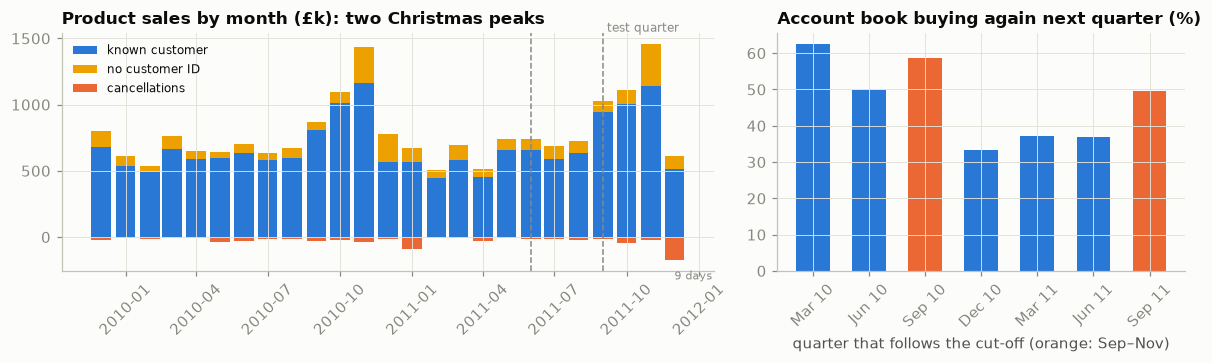

In [4]:
known = purchase.customer.notna()
m = purchase.assign(month=purchase.ts.dt.to_period("M"), known=known).groupby(["month", "known"]).value.sum().unstack()
m_canc = cancel.assign(month=cancel.ts.dt.to_period("M")).groupby("month").value.sum()
kp = purchase[known]
rep = []
for T in CUTOFFS:
    book = kp[(kp.ts >= T - pd.DateOffset(months=ACTIVE_MONTHS)) & (kp.ts < T)].customer.unique()
    nxt = kp[(kp.ts >= T) & (kp.ts < T + pd.DateOffset(months=HORIZON_MONTHS))].customer.unique()
    rep.append({"cut-off": f"{T:%d %b %Y}", "next quarter": f"{T:%b}–{T + pd.DateOffset(months=2):%b %Y}", "account book": len(book),
                "buy again": np.isin(book, nxt).mean(), "new customers": len(set(nxt) - set(book))})
rep = pd.DataFrame(rep).set_index("cut-off")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
t_ = m.index.to_timestamp()
ax.bar(t_, m[True] / 1e3, width=25, color=SERIES[0], label="known customer")
ax.bar(t_, m[False] / 1e3, width=25, bottom=m[True] / 1e3, color=SERIES[3], label="no customer ID")
ax.bar(m_canc.index.to_timestamp(), m_canc.values / 1e3, width=25, color=SERIES[1], label="cancellations")
for x in [VALID_CUTOFF, TEST_CUTOFF]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
ax.text(TEST_CUTOFF, 1550, " test quarter", color=MUTED, fontsize=8); ax.text(pd.Timestamp("2011-12-01"), -320, "9 days", color=MUTED, fontsize=7)
ax.set_title("Product sales by month (£k): two Christmas peaks"); ax.legend(fontsize=8, loc="upper left"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.bar(rep["next quarter"].str[:3] + " " + rep.index.str[-2:], rep["buy again"] * 100, width=0.6,
       color=[SERIES[1] if q.startswith("Sep") else SERIES[0] for q in rep["next quarter"]])
ax.set_title("Account book buying again next quarter (%)"); ax.set_xlabel("quarter that follows the cut-off (orange: Sep–Nov)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
display(rep.style.format({"account book": "{:,}", "buy again": "{:.1%}", "new customers": "{:,}"}))

In [5]:
book_rev = kp[(kp.ts >= TEST_CUTOFF - pd.DateOffset(months=12)) & (kp.ts < TEST_CUTOFF)].groupby("customer", observed=True).value.sum().sort_values(ascending=False)
ctry = kp.groupby("customer", observed=True).country.agg(lambda s: s.mode().iloc[0])
print(f"account book at {TEST_CUTOFF:%d %b %Y}: {len(book_rev):,} customers · the top {CALLS_PER_QUARTER} hold "
      f"{book_rev.head(CALLS_PER_QUARTER).sum()/book_rev.sum():.0%} of the last 12 months' purchases · median customer £{book_rev.median():,.0f} · "
      f"UK customers {(ctry.reindex(book_rev.index) == 'United Kingdom').mean():.0%}")
xmas = {y: purchase[(purchase.ts >= f"{y}-09-01") & (purchase.ts < f"{y}-12-01")].value.sum() for y in (2010, 2011)}
year = {y: purchase[(purchase.ts >= f"{y - 1}-12-01") & (purchase.ts < f"{y}-12-01")].value.sum() for y in (2010, 2011)}
print("Sep–Nov product sales: " + " · ".join(f"{y} £{xmas[y]/1e6:.2f}M ({xmas[y]/year[y]:.0%} of the twelve months to November)" for y in xmas))

account book at 01 Sep 2011: 4,324 customers · the top 200 hold 47% of the last 12 months' purchases · median customer £640 · UK customers 91%
Sep–Nov product sales: 2010 £3.41M (36% of the twelve months to November) · 2011 £3.59M (37% of the twelve months to November)


September–November sold £3.41M in 2010 and £3.59M in 2011, 36–37 % of each year. Buying again follows the season: once the book has a year behind it, 33–37 % of it buys in each quarter from December to August and 50 % in Sep–Nov 2011. The book is concentrated: the top 200 of 4,324 customers hold 47 % of the last twelve months' purchases; the median customer bought £640. Each quarter also brings 273–990 buyers from outside the book.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Who buys next quarter: features at the cut-off, three families of model

*Part B · Given model · package `make_panel`, the BG/NBD functions, `fit_models` and `evaluate` unchanged and reproduce the numbers (C2).*

**The panel.** At each quarterly cut-off *T* the *account book* is every customer with a purchase in the twelve months before *T*; features read only rows before *T*, the outcome only the quarter after. Seven cut-offs give 24,824 customer-quarters. Settings are chosen on Jun–Aug 2011; the test model trains on every quarter that ended by 1 September 2011 and is scored once on Sep–Nov 2011. Revenue is *net* of cancellations, products only, identified customers only (Section 6 shows why).

**The candidates**, from the legacy spreadsheet to a learned model:

- **the spreadsheet**: rank by last-twelve-months revenue, forecast a quarter's worth of it (the *run-rate*); and **same quarter last year**, the seasonal naive forecast;
- **RFM**: recency, frequency and monetary quintiles summed to 3–15, each score's buy rate and mean revenue from the training quarters;
- **BG/NBD + Gamma-Gamma** (Fader, Hardie and Lee, 2005), written in `scipy` without extra packages: buying days as transactions, refitted at each cut-off;
- **LightGBM**: a classifier for *buys again* and a Tweedie regressor for revenue, on 18 features including the season of the target quarter.

**Metrics.** AUC ranks who buys again; *P(buy) ÷ realised* and *forecast ÷ realised* check the level planning needs; MAE the revenue per customer. Two capacity metrics follow two call lists: the quarter's revenue held by the 200 forecast to spend most (*grow*), and the lapsed customers' run-rate reached by the 200 with the highest (1 − P(buy)) × run-rate (*save*).

In [6]:
SEASON = {12: "Dec–Feb", 3: "Mar–May", 6: "Jun–Aug", 9: "Sep–Nov"}
TOP_COUNTRIES = ["United Kingdom", "EIRE", "Germany", "France", "Netherlands"]

def customer_lines(src: pd.DataFrame, products_only: bool = True) -> pd.DataFrame:
    """Product purchases and cancellations of identified customers: the only rows a customer feature may read."""
    d = src[(src.is_product | (not products_only)) & src.customer.notna() & (src.price > 0) & (src.is_cancel | (src.quantity > 0))]
    d = d[["customer", "invoice", "ts", "stock_code", "value", "is_cancel", "country"]].copy()
    d["customer"] = d.customer.astype(str)
    d["day"] = d.ts.dt.floor("D")
    return d

cust_lines = customer_lines(lines)

def customer_table(T: pd.Timestamp, src: pd.DataFrame = None) -> pd.DataFrame:
    """Features known at cut-off T (rows before T only) and the next quarter's outcome (rows in [T, T + 3 months))."""
    src = cust_lines if src is None else src
    h = src[src.ts < T]
    buys, canc = h[~h.is_cancel], h[h.is_cancel]
    inv = buys.groupby(["customer", "invoice"]).agg(ts=("ts", "min"), value=("value", "sum")).reset_index()
    book = inv.loc[inv.ts >= T - pd.DateOffset(months=ACTIVE_MONTHS), "customer"].unique()
    g = inv.groupby("customer")
    X = pd.DataFrame(index=pd.Index(np.sort(book), name="customer"))
    first, last, n_all = g.ts.min().reindex(X.index), g.ts.max().reindex(X.index), g.size().reindex(X.index)
    X["recency_days"] = (T - last).dt.days
    X["tenure_days"] = (T - first).dt.days
    X["gap_mean_days"] = ((last - first).dt.days / (n_all - 1)).where(n_all > 1)
    def net(a, b):          # net product revenue in [a, b): purchases minus cancellations dated in the window
        w = h[(h.ts >= a) & (h.ts < b)]
        return w.groupby("customer").value.sum().reindex(X.index).fillna(0.0)
    for d in (90, 365):
        X[f"orders_{d}"] = inv[inv.ts >= T - pd.Timedelta(days=d)].groupby("customer").size().reindex(X.index).fillna(0)
        X[f"rev_{d}"] = net(T - pd.Timedelta(days=d), T)
    X["orders_all"], X["rev_all"] = n_all, net(WINDOW_START, T)
    b365 = buys[buys.ts >= T - pd.Timedelta(days=365)]
    X["aov_365"] = b365.groupby("customer").value.sum().reindex(X.index) / X.orders_365
    X["items_365"] = b365.groupby("customer").stock_code.nunique().reindex(X.index).fillna(0)
    c365 = canc[canc.ts >= T - pd.Timedelta(days=365)].groupby("customer").value.sum().reindex(X.index).fillna(0)
    X["return_share_365"] = (-c365 / b365.groupby("customer").value.sum().reindex(X.index)).clip(0, 1)
    X["rev_prev_q"] = net(T - pd.DateOffset(months=3), T)
    X["rev_q_before"] = net(T - pd.DateOffset(months=6), T - pd.DateOffset(months=3))
    ly = T - pd.DateOffset(months=12)
    X["rev_same_q_last_year"] = net(ly, ly + pd.DateOffset(months=HORIZON_MONTHS)) if ly >= WINDOW_START else np.nan
    X["run_rate_q"] = X.rev_365.clip(lower=0) * 91 / X.tenure_days.clip(lower=91, upper=365)   # a quarter's worth of the last year
    cty = buys.sort_values("ts").groupby("customer").country.last().reindex(X.index).astype(str)
    X["country"] = cty.where(cty.isin(TOP_COUNTRIES), "Other")
    X["season"] = SEASON[T.month]
    # ---- the outcome: the next quarter, never a feature ----
    f = src[(src.ts >= T) & (src.ts < T + pd.DateOffset(months=HORIZON_MONTHS))]
    X["y_buy"] = X.index.isin(f.loc[~f.is_cancel, "customer"].unique()).astype(int)
    X["y_rev"] = f.groupby("customer").value.sum().reindex(X.index).fillna(0.0).clip(lower=0)
    X["cutoff"] = T
    return X

def make_panel(src=None):
    p = pd.concat([customer_table(T, src) for T in CUTOFFS]).reset_index()
    p["country"] = p.country.astype("category")
    p["season"] = pd.Categorical(p.season, categories=list(SEASON.values()))
    return p

t0 = time.time()
panel = make_panel()
FEATURES = ["recency_days", "tenure_days", "gap_mean_days", "orders_90", "orders_365", "orders_all", "rev_90", "rev_365", "rev_all",
            "aov_365", "items_365", "return_share_365", "rev_prev_q", "rev_q_before", "rev_same_q_last_year", "run_rate_q", "country", "season"]
print(f"panel: {len(panel):,} customer-quarters from {len(CUTOFFS)} cut-offs, {len(FEATURES)} features, built in {time.time()-t0:.1f}s")

panel: 24,824 customer-quarters from 7 cut-offs, 18 features, built in 3.9s


In [7]:
# ---- the classic probabilistic baseline: BG/NBD (Fader, Hardie & Lee 2005) + Gamma-Gamma spend, written with scipy ----
def bgnbd_inputs(T: pd.Timestamp) -> pd.DataFrame:
    days = cust_lines[cust_lines.ts < T].groupby(["customer", "day"]).value.sum().reset_index()   # a transaction = a buying day
    g = days[days.value > 0].groupby("customer")
    d = pd.DataFrame({"x": g.size() - 1, "first": g.day.min(), "last": g.day.max(), "spend": g.value.mean()})
    d["t_x"], d["T"] = (d["last"] - d["first"]).dt.days / 7, (T - d["first"]).dt.days / 7      # weeks
    return d

def bgnbd_fit(x, tx, Tc):
    def nll(lp):
        r, alpha, a, b = np.exp(lp)
        common = special.gammaln(r + x) - special.gammaln(r) + r * np.log(alpha) + special.betaln(a, b + x) - special.betaln(a, b)
        alive = -(r + x) * np.log(alpha + Tc)
        dropped = np.where(x > 0, np.log(a) - np.log(np.maximum(b + x - 1, 1e-12)) - (r + x) * np.log(alpha + tx), -np.inf)
        return -(common + np.logaddexp(alive, dropped)).sum()
    res = optimize.minimize(nll, np.log([0.5, 5.0, 0.5, 2.0]), method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-7, "fatol": 1e-7})
    return np.exp(res.x)

def bgnbd_predict(params, x, tx, Tc, t):
    r, alpha, a, b = params
    denom = 1 + np.where(x > 0, a / np.maximum(b + x - 1, 1e-12) * ((alpha + Tc) / (alpha + tx)) ** (r + x), 0.0)
    no_buy_if_alive = ((alpha + Tc) / (alpha + Tc + t)) ** (r + x)
    hyp = special.hyp2f1(r + x, b + x, a + b + x - 1, t / (alpha + Tc + t))
    expected = (a + b + x - 1) / (a - 1) * (1 - no_buy_if_alive * hyp) / denom
    return expected, (1 - no_buy_if_alive) / denom          # E[transactions in t], P(at least one)

def gamma_gamma_fit(n, mx):
    def nll(lp):
        p, q, v = np.exp(lp)
        return -(special.gammaln(p * n + q) - special.gammaln(p * n) - special.gammaln(q) + q * np.log(v)
                 + (p * n - 1) * np.log(mx) + p * n * np.log(n) - (p * n + q) * np.log(n * mx + v)).sum()
    return np.exp(optimize.minimize(nll, np.log([1.0, 2.0, 100.0]), method="Nelder-Mead", options={"maxiter": 5000}).x)

def bgnbd_forecast(T):
    d = bgnbd_inputs(T)
    bg_params = bgnbd_fit(d.x.values, d.t_x.values, d["T"].values)
    t = ((T + pd.DateOffset(months=HORIZON_MONTHS)) - T).days / 7
    e, p_buy = bgnbd_predict(bg_params, d.x.values, d.t_x.values, d["T"].values, t)
    rep_ = d[(d.x > 0) & (d.spend > 0)]
    p, q, v = gg_params = gamma_gamma_fit(rep_.x.values + 1.0, rep_.spend.values)
    n = d.x.values + 1.0
    spend = p * (v + n * d.spend.values.clip(min=1)) / (p * n + q - 1)
    return pd.DataFrame({"p_bg": p_buy, "rev_bg": e * spend}, index=d.index), bg_params, gg_params

t0 = time.time()
bg = {}
for T in CUTOFFS[-4:]:
    bg[T], prm, ggp = bgnbd_forecast(T)
    if T >= VALID_CUTOFF:
        print(f"BG/NBD at {T:%d %b %Y}: r={prm[0]:.3f} α={prm[1]:.2f} a={prm[2]:.3f} b={prm[3]:.3f} · "
              f"Gamma-Gamma p={ggp[0]:.2f} q={ggp[1]:.2f} γ={ggp[2]:.0f}")
print(f"fitted at {len(bg)} cut-offs in {time.time()-t0:.1f}s")

BG/NBD at 01 Jun 2011: r=0.689 α=9.72 a=0.149 b=3.285 · Gamma-Gamma p=2.22 q=3.65 γ=489


BG/NBD at 01 Sep 2011: r=0.645 α=9.27 a=0.177 b=2.913 · Gamma-Gamma p=2.17 q=3.66 γ=493
fitted at 4 cut-offs in 3.1s


In [8]:
CLF = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
REG = dict(CLF, objective="tweedie", tweedie_variance_power=1.3)
K_CALLS = CALLS_PER_QUARTER

def rfm_score(d):
    """Classic RFM: quintiles of recency, frequency (orders in 12 months) and monetary (12-month net revenue), summed to 3–15."""
    q = lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1
    return q(-d.recency_days) + q(d.orders_365) + q(d.rev_365)

def evaluate(name, d, p_buy, rev_hat, risk=None, k=K_CALLS):
    y, r, rr = d.y_buy.values, d.y_rev.values, d.run_rate_q.values
    p_buy, rev_hat = np.asarray(p_buy, float), np.asarray(rev_hat, float)
    risk = (1 - p_buy) * rr if risk is None else np.asarray(risk, float)
    grow = np.argsort(-rev_hat, kind="stable")[:k]
    save = np.argsort(-risk, kind="stable")[:k]
    lapsed = (y == 0)
    return {"model": name, "AUC (buys again)": roc_auc_score(y, p_buy),
            "P(buy) ÷ realised": p_buy.mean() / y.mean() if p_buy.max() <= 1 else np.nan,
            "MAE £": mean_absolute_error(r, rev_hat), "forecast ÷ realised": rev_hat.sum() / r.sum(),
            f"revenue in top {k}": r[grow].sum() / r.sum(),
            f"lapsed run-rate in top {k}": (rr[save] * lapsed[save]).sum() / (rr * lapsed).sum()}

def fit_models(train, cols=FEATURES):
    clf = lgb.LGBMClassifier(**CLF).fit(train[cols], train.y_buy)
    reg = lgb.LGBMRegressor(**REG).fit(train[cols], train.y_rev)
    return clf, reg

def split(T, data=None):
    data = panel if data is None else data
    return data[data.cutoff + pd.DateOffset(months=HORIZON_MONTHS) <= T], data[data.cutoff == T].copy()

def compare(T):
    train, test = split(T)
    rfm_tr = train.assign(rfm=train.groupby("cutoff", group_keys=False).apply(rfm_score))
    cell = rfm_tr.groupby("rfm").agg(p=("y_buy", "mean"), rev=("y_rev", "mean"))
    test["rfm"] = rfm_score(test)
    b = bg[T].reindex(test.customer.values)
    clf, reg = fit_models(train)
    test["p_lgb"], test["rev_lgb"] = clf.predict_proba(test[FEATURES])[:, 1], reg.predict(test[FEATURES])
    test["p_bg"], test["rev_bg"] = b.p_bg.fillna(0).values, b.rev_bg.fillna(0).values
    silent = test.run_rate_q * (test.recency_days >= SILENT_DAYS)
    rows = [evaluate("spreadsheet: last 12 months", test, test.rev_365, test.run_rate_q, risk=silent),
            evaluate("same quarter last year", test, test.rev_same_q_last_year.fillna(0), test.rev_same_q_last_year.fillna(0).clip(lower=0)),
            evaluate("RFM score (cell means)", test, test.rfm.map(cell.p).values, test.rfm.map(cell.rev).values),
            evaluate("BG/NBD + Gamma-Gamma", test, test.p_bg, test.rev_bg),
            evaluate("LightGBM", test, test.p_lgb, test.rev_lgb)]
    hindsight = {"revenue": test.y_rev.nlargest(K_CALLS).sum() / test.y_rev.sum(),
                 "lapsed": (test.run_rate_q * (1 - test.y_buy)).nlargest(K_CALLS).sum() / (test.run_rate_q * (1 - test.y_buy)).sum()}
    return pd.DataFrame(rows).set_index("model"), test, clf, reg, hindsight, len(train)

FMT = {"AUC (buys again)": "{:.3f}", "P(buy) ÷ realised": "{:.2f}", "MAE £": "{:,.0f}", "forecast ÷ realised": "{:.2f}",
       f"revenue in top {K_CALLS}": "{:.1%}", f"lapsed run-rate in top {K_CALLS}": "{:.1%}"}
res_va, scored_va, _, _, hind_va, n_va = compare(VALID_CUTOFF)
res_te, scored, clf, reg, hind_te, n_te = compare(TEST_CUTOFF)
RELEVEL = scored_va.y_rev.sum() / scored_va.rev_lgb.sum()      # realised ÷ forecast on the last matured quarter
scored["rev_lgb_relevelled"] = scored.rev_lgb * RELEVEL
print(f"validation: train on {n_va:,} customer-quarters, score Jun–Aug 2011 · hindsight: revenue {hind_va['revenue']:.1%}, lapsed {hind_va['lapsed']:.1%}")
display(res_va.style.format(FMT, na_rep="–"))
print(f"test: train on {n_te:,} customer-quarters, score Sep–Nov 2011 · hindsight: revenue {hind_te['revenue']:.1%}, lapsed {hind_te['lapsed']:.1%}")
display(res_te.style.format(FMT, na_rep="–"))
print(f"re-levelling factor from Jun–Aug 2011: ×{RELEVEL:.2f} → LightGBM forecast ÷ realised on Sep–Nov 2011 "
      f"{scored.rev_lgb_relevelled.sum() / scored.y_rev.sum():.2f}, MAE £{mean_absolute_error(scored.y_rev, scored.rev_lgb_relevelled):,.0f}")
# How sure is the AUC lead? Bootstrap the customers of the test quarter
rng = np.random.default_rng(SEED)
yb, rivals = scored.y_buy.values, {"BG/NBD": scored.p_bg.values, "spreadsheet": scored.rev_365.values}
boot = {k: [] for k in rivals}
for _ in range(300):
    i = rng.integers(0, len(yb), len(yb))
    a = roc_auc_score(yb[i], scored.p_lgb.values[i])
    for k, v in rivals.items():
        boot[k].append(a - roc_auc_score(yb[i], v[i]))
print("LightGBM's AUC lead, 95 % bootstrap interval (300 resamples): " + " · ".join(
    f"over {k} {roc_auc_score(yb, scored.p_lgb) - roc_auc_score(yb, v):+.3f} [{np.percentile(boot[k], 2.5):+.3f}, {np.percentile(boot[k], 97.5):+.3f}]"
    for k, v in rivals.items()))
# The frozen holdout the CI gate scores: fingerprint it so a silent change is refused
holdout = panel[panel.cutoff == TEST_CUTOFF].sort_values("customer")
HOLDOUT_SHA256 = hashlib.sha256(holdout.to_csv(index=False).encode()).hexdigest()
print(f"frozen holdout (Sep–Nov 2011): {len(holdout):,} customers · SHA-256 {HOLDOUT_SHA256[:16]}…")

validation: train on 16,176 customer-quarters, score Jun–Aug 2011 · hindsight: revenue 60.1%, lapsed 36.0%


,AUC (buys again),P(buy) ÷ realised,MAE £,forecast ÷ realised,revenue in top 200,lapsed run-rate in top 200
model,,,,,,
spreadsheet: last 12 months,0.759,–,367,1.43,51.1%,18.4%
same quarter last year,0.651,–,384,1.08,43.5%,15.3%
RFM score (cell means),0.792,1.23,508,1.36,25.7%,22.1%
BG/NBD + Gamma-Gamma,0.807,1.13,308,1.12,52.4%,24.0%
LightGBM,0.806,0.90,270,0.73,51.7%,24.1%


test: train on 20,500 customer-quarters, score Sep–Nov 2011 · hindsight: revenue 53.7%, lapsed 45.8%


,AUC (buys again),P(buy) ÷ realised,MAE £,forecast ÷ realised,revenue in top 200,lapsed run-rate in top 200
model,,,,,,
spreadsheet: last 12 months,0.746,–,439,0.88,46.3%,25.1%
same quarter last year,0.653,–,525,1.11,43.3%,21.8%
RFM score (cell means),0.763,0.88,591,0.80,21.7%,25.4%
BG/NBD + Gamma-Gamma,0.766,0.81,427,0.68,46.0%,27.6%
LightGBM,0.778,0.81,412,0.72,46.1%,26.5%


re-levelling factor from Jun–Aug 2011: ×1.37 → LightGBM forecast ÷ realised on Sep–Nov 2011 0.98, MAE £424


LightGBM's AUC lead, 95 % bootstrap interval (300 resamples): over BG/NBD +0.011 [+0.004, +0.019] · over spreadsheet +0.032 [+0.023, +0.040]
frozen holdout (Sep–Nov 2011): 4,324 customers · SHA-256 2dc34804a071ba91…


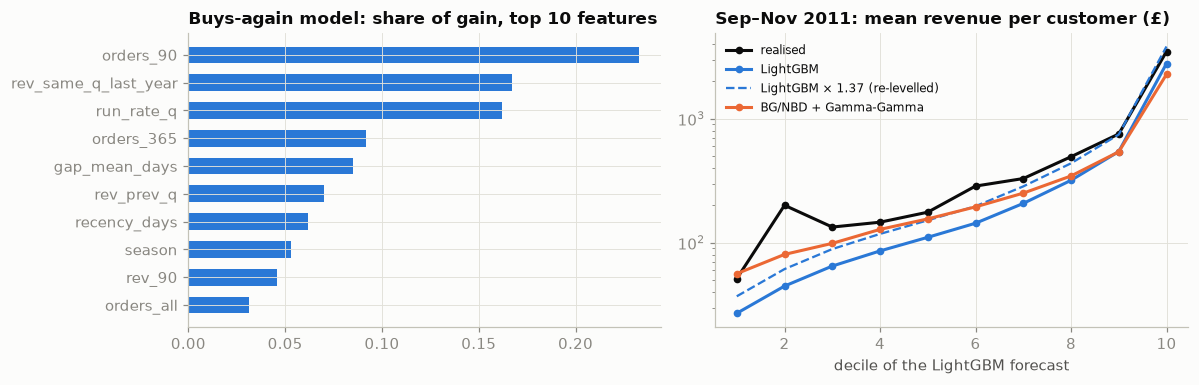

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
imp = pd.Series(clf.booster_.feature_importance("gain"), index=FEATURES).sort_values(ascending=False).head(10)
ax.barh(imp.index[::-1], (imp / imp.sum()).values[::-1], color=SERIES[0], height=0.6)
ax.set_title("Buys-again model: share of gain, top 10 features")
ax = axes[1]
sc = scored.assign(band=pd.qcut(scored.rev_lgb.rank(method="first"), 10, labels=False) + 1)
cal = sc.groupby("band").agg(real=("y_rev", "mean"), lgb_=("rev_lgb", "mean"), rel=("rev_lgb_relevelled", "mean"), bg_=("rev_bg", "mean"))
ax.plot(cal.index, cal.real, "-o", ms=4, lw=2, color=INK, label="realised")
ax.plot(cal.index, cal.lgb_, "-o", ms=4, lw=2, color=SERIES[0], label="LightGBM")
ax.plot(cal.index, cal.rel, "--", lw=1.5, color=SERIES[0], label=f"LightGBM × {RELEVEL:.2f} (re-levelled)")
ax.plot(cal.index, cal.bg_, "-o", ms=4, lw=2, color=SERIES[1], label="BG/NBD + Gamma-Gamma")
ax.set_yscale("log"); ax.set_xlabel("decile of the LightGBM forecast"); ax.set_title("Sep–Nov 2011: mean revenue per customer (£)")
ax.legend(fontsize=8)
plt.tight_layout()

**Read the test table by column.** Ranking who buys again, LightGBM leads (AUC 0.778) over BG/NBD (0.766), RFM (0.763) and the spreadsheet (0.746); the bootstrap puts its lead at +0.011 [0.004, 0.019] over BG/NBD and +0.032 [0.023, 0.040] over the spreadsheet. It leans on recent orders, the same quarter last year and the run-rate (left chart). Revenue per customer: MAE £412 against £427 and £439. Picking the 200 biggest is a tie: 46.1 % of the quarter's revenue against 46.3 % (spreadsheet) and 46.0 % (BG/NBD); hindsight 53.7 %.

**The level is wrong for every model.** LightGBM forecasts 0.72 of what the book bought in September–November, BG/NBD 0.68, and LightGBM was already at 0.73 on Jun–Aug. Every decile is under-forecast (right chart). A likely cause, not tested here: early quarters hold short histories, and trees cannot extrapolate beyond the accounts they saw. Re-levelling by the last matured quarter (×1.37, from Jun–Aug) brings the Christmas total to 0.98 at a slightly higher MAE (£424). The ranking, and so the call list, is unchanged. Gate ranking and level separately (task C4).

## 4 · The call list: 200 calls, two ways to spend them

*Part B · Given model · package `capture` and `list_stats`; C3 asks you to own call cost and win-back rate.*

A call can **grow** an account that will buy anyway or **save** one going quiet. Either's worth depends on what a call changes, which this data cannot show: we rank both lists, measure what each reaches, and state the assumed win-back rate openly.

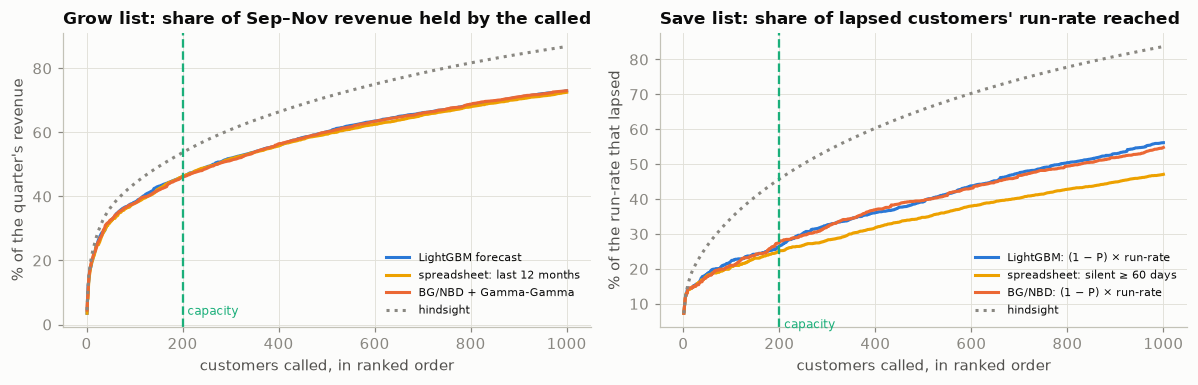

In [10]:
K = np.arange(1, 1001)
def capture(score, value):
    order = np.argsort(-np.asarray(score, float), kind="stable")
    return np.cumsum(np.asarray(value, float)[order])[K - 1] / np.sum(value)
lapsed_rr = (scored.run_rate_q * (1 - scored.y_buy)).values
risk_lgb, risk_bg = (1 - scored.p_lgb) * scored.run_rate_q, (1 - scored.p_bg) * scored.run_rate_q
risk_sheet = scored.run_rate_q * (scored.recency_days >= SILENT_DAYS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, title, ylab, curves in [
    (axes[0], "Grow list: share of Sep–Nov revenue held by the called", "% of the quarter's revenue",
     [("LightGBM forecast", scored.rev_lgb, scored.y_rev, SERIES[0]), ("spreadsheet: last 12 months", scored.run_rate_q, scored.y_rev, SERIES[3]),
      ("BG/NBD + Gamma-Gamma", scored.rev_bg, scored.y_rev, SERIES[1]), ("hindsight", scored.y_rev, scored.y_rev, MUTED)]),
    (axes[1], "Save list: share of lapsed customers' run-rate reached", "% of the run-rate that lapsed",
     [("LightGBM: (1 − P) × run-rate", risk_lgb, lapsed_rr, SERIES[0]), (f"spreadsheet: silent ≥ {SILENT_DAYS} days", risk_sheet, lapsed_rr, SERIES[3]),
      ("BG/NBD: (1 − P) × run-rate", risk_bg, lapsed_rr, SERIES[1]), ("hindsight", lapsed_rr, lapsed_rr, MUTED)])]:
    for name, s, v, col in curves:
        ax.plot(K, capture(s, v) * 100, lw=2, color=col, ls=":" if name == "hindsight" else "-", label=name)
    ax.axvline(K_CALLS, color=SERIES[2], lw=1.5, ls="--"); ax.text(K_CALLS + 10, 3, "capacity", color=SERIES[2], fontsize=8)
    ax.set_xlabel("customers called, in ranked order"); ax.set_ylabel(ylab); ax.set_title(title); ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout()

In [11]:
top_m, top_s = set(scored.nlargest(K_CALLS, "rev_lgb").customer), set(scored.nlargest(K_CALLS, "run_rate_q").customer)
print(f"grow lists: LightGBM's and the spreadsheet's {K_CALLS} share {len(top_m & top_s)} customers")
def list_stats(score, name, k=K_CALLS):
    top = scored.iloc[np.argsort(-np.asarray(score, float), kind="stable")[:k]]
    return {"list": name, "lapsed (did not buy)": int((top.y_buy == 0).sum()), "their run-rate £": (top.run_rate_q * (1 - top.y_buy)).sum(),
            "bought anyway": int(top.y_buy.sum()), "Sep–Nov revenue £": top.y_rev.sum()}
lists = pd.DataFrame([list_stats(scored.rev_lgb, "grow: LightGBM forecast"), list_stats(scored.run_rate_q, "grow: spreadsheet"),
                      list_stats(risk_lgb, "save: LightGBM risk"), list_stats(risk_sheet, f"save: silent ≥ {SILENT_DAYS} days"),
                      list_stats(risk_bg, "save: BG/NBD risk")]).set_index("list")
display(lists.style.format({"their run-rate £": "{:,.0f}", "Sep–Nov revenue £": "{:,.0f}"}))

# The operating point: a save call is worth making if WIN_BACK_RATE × margin × expected lapsed run-rate covers its cost
value_per_call = WIN_BACK_RATE * GROSS_MARGIN * risk_lgb - CALL_COST_GBP
n_worth = int((value_per_call > 0).sum()); K_STAR = min(K_CALLS, n_worth)
chosen = scored.iloc[np.argsort(-risk_lgb.values, kind="stable")[:K_STAR]]
grow_fill = scored[~scored.customer.isin(set(chosen.customer))].nlargest(K_CALLS - K_STAR, "run_rate_q")   # rest of capacity: biggest accounts
plan = pd.concat([chosen, grow_fill])
print(f"the plan within capacity: {K_STAR} save calls + {len(grow_fill)} grow calls (biggest accounts not on the save list) = {len(plan)} · "
      f"the grow calls hold {grow_fill.y_rev.sum() / scored.y_rev.sum():.1%} of the quarter's revenue, the whole plan {plan.y_rev.sum() / scored.y_rev.sum():.1%}; "
      f"calling the spreadsheet's top {K_CALLS} instead would hold {lists.loc['grow: spreadsheet', 'Sep–Nov revenue £'] / scored.y_rev.sum():.1%}")
print(f"a save call breaks even at £{CALL_COST_GBP / (WIN_BACK_RATE * GROSS_MARGIN):,.0f} of expected lapsed run-rate: "
      f"{n_worth} customers clear it, capacity {K_CALLS} → call {K_STAR}")
print(f"expected value of the {K_STAR} calls (model's own estimate): £{value_per_call.nlargest(K_STAR).sum():,.0f} · "
      f"if the win-back rate were real, on the lapses that happened: £{WIN_BACK_RATE * GROSS_MARGIN * (chosen.run_rate_q * (1 - chosen.y_buy)).sum() - CALL_COST_GBP * K_STAR:,.0f}")
sens = []
for wb in (0.05, 0.10, 0.20, 0.40):
    for cost in (20.0, 40.0, 80.0):
        v = wb * GROSS_MARGIN * risk_lgb - cost
        k_ = min(K_CALLS, int((v > 0).sum()))
        sel = scored.iloc[np.argsort(-risk_lgb.values, kind="stable")[:k_]]
        sens.append({"win-back rate": wb, "call cost £": cost, "calls": k_,
                     "net value £ on realised lapses": wb * GROSS_MARGIN * (sel.run_rate_q * (1 - sel.y_buy)).sum() - cost * k_})
sens = pd.DataFrame(sens).pivot(index="win-back rate", columns="call cost £", values=["calls", "net value £ on realised lapses"])
sens.index = pd.Index([f"{v:.0%}" for v in sens.index], name="win-back rate")
sens.columns = pd.MultiIndex.from_tuples([(a, f"£{b:.0f} a call") for a, b in sens.columns])
display(sens.style.format("{:,.0f}"))

grow lists: LightGBM's and the spreadsheet's 200 share 157 customers


,lapsed (did not buy),their run-rate £,bought anyway,Sep–Nov revenue £
list,,,,
grow: LightGBM forecast,15,"68,883",185,"1,207,547"
grow: spreadsheet,19,"106,103",181,"1,212,664"
save: LightGBM risk,75,"144,094",125,"598,596"
save: silent ≥ 60 days,72,"136,691",128,"183,990"
save: BG/NBD risk,77,"150,045",123,"573,294"


the plan within capacity: 102 save calls + 98 grow calls (biggest accounts not on the save list) = 200 · the grow calls hold 27.6% of the quarter's revenue, the whole plan 41.9%; calling the spreadsheet's top 200 instead would hold 46.3%
a save call breaks even at £571 of expected lapsed run-rate: 102 customers clear it, capacity 200 → call 102
expected value of the 102 calls (model's own estimate): £5,669 · if the win-back rate were real, on the lapses that happened: £4,478


**Grow.** LightGBM's 200 and the spreadsheet's share 157 customers and both reach about £1.21M; 185 and 181 bought anyway. The model adds nothing, and whether a call changes an order already coming is unknown.

**Save.** LightGBM's 200 riskiest include 75 customers who then bought nothing, carrying £144k of quarterly run-rate; BG/NBD 77 (£150k); the spreadsheet's *big and silent for 60 days*, 72 (£137k); hindsight 45.8 % of the lapsed run-rate.

**The operating point.** A save call pays if `WIN_BACK_RATE` × margin × expected lapsed run-rate covers its £40: at an assumed 20 %, £571, which 102 customers clear; they would net about £4.5k a quarter on the lapses that happened. At 5 % only 11 calls pay, at 40 % all 200 (£12.2k). **The answer to the board, within 200 calls:** the 102 save calls that pay, ranked by the model, and the other 98 to the biggest accounts not already on that list, by the spreadsheet. The plan covers 41.9 % of the quarter's revenue against 46.3 % for the spreadsheet's top 200: 4.4 points paid for the save list. Run it as an experiment, a random half of the save calls held back for the next-biggest accounts, because nobody has measured the win-back rate (task C3).

## 5 · What to offer: a forward-evaluated recommender and a product taxonomy

*Part B · Given model · package `build_taxonomy`, `knn_scores`, `cold_start` and `context_pack`; E1 is the taxonomy ablation, S1 uses the pack.*

A call needs an offer, in two lists:

- **from the range**: codes the customer has never bought, ranked by item-kNN (cosine on the last twelve months' purchases, 50 neighbours), against 90-day popularity;
- **new this season**: codes first sold in the quarter, which co-purchase cannot score, ranked by content against the customer's purchase profile. We assume the season's range is in the catalogue at the cut-off.

Content comes in two kinds: the **taxonomy** (method: *keyword rules*, hand-written regular expressions on the normalised description) with 16 categories, a season tag and attribute tags; and the **words**, a TF-IDF vector of the description. The ablation asks whether the taxonomy, our knowledge base, adds anything the words do not.

In [12]:
def norm_desc(s) -> str:
    """Deterministic normaliser: upper case, punctuation to spaces, single spaces."""
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9 ]+", " ", str(s).upper())).strip()

# ---- a rule-based product taxonomy from the free-text descriptions (first matching rule wins; order matters) ----
CATEGORIES = [
    ("candles & fragrance", r"\w*CANDLES?|CANDLEHOLDERS?|T ?LIGHTS?|TEA ?LIGHTS?|TLIGHTS?|INCENSE|OIL BURNER|SCENTED|FRAGRANCE|DIFFUSER|WAX"),
    ("giftwrap & cards", r"WRAP|WRAPPING|GIFT BAGS?|GIFT TAGS?|TAGS|TISSUES?|CARDS?|ENVELOPES?|RIBBONS?|BOWS?"),
    ("Christmas decorations", r"CHRISTMAS|XMAS|ADVENT|SANTA|REINDEER|SNOWFLAKES?|SNOWMAN|NOEL|BAUBLES?|NATIVITY|STOCKING|SLEIGH"),
    ("bags & purses", r"BAGS?|SHOPPER|TOTE|PURSE|HANDBAG|RUCKSACK|BACKPACK|WASHBAG"),
    ("jewellery & accessories", r"NECKLACE|BRACELET|EARRINGS|BROOCH|BANGLE|PENDANT|CHARM|DIAMANTE|JEWEL\w*|HAIR\w*|RINGS?|CHOKER|TIARAS?|UMBRELLA|SCARF|SUNGLASSES|KEYRING|HAND WARMER|PONCHO|SOMBRERO|CLIPS"),
    ("kitchen & tableware", r"MUGS?|CUPS?|SAUCERS?|TEACUPS?|PLATES?|BOWLS?|JUGS?|TEAPOT|CAKE ?STANDS?|CUTLERY|SPOONS?|FORKS?|NAPKINS?|TRAYS?|DISH|"
                            r"TUMBLERS?|BEAKERS?|GLASS(ES)?|COASTERS?|PLACEMATS?|TEA TOWELS?|APRON|OVEN GLOVE|BAKING|CAKE CASES|CASES|COOKIE|CUTTERS?|"
                            r"MOULDS?|JARS?|BOTTLES?|LUNCH BOX|PANTRY|KITCHEN|CHOPPING|STRAWS|BISCUIT|CAKE TINS?|EGG CUPS?|DOILIES|DOILY|CONTAINER|TEA FOR ONE|POPCORN|TEA SET|COFFEE SET|TEA COFFEE SUGAR|JAM MAKING|"
                            r"BREAD BIN|FRYING PAN|WASHING UP|CLOTHES PEGS|EGG HOLDER"),
    ("lighting", r"LIGHTS?|NIGHTLIGHT|LANTERNS?|LAMPS?|LAMPSHADE|LED|TORCH"),
    ("storage & boxes", r"BOX|BOXES|TINS?|BASKETS?|STORAGE|CRATES?|DRAWERS?|CHEST|CHESTS|TRUNK|HAMPER"),
    ("toys & children", r"TOYS?|GAMES?|DOLLS?|DOLLY|PUZZLES?|JIGSAW|SPACEBOY|CHILDRENS|CHILDS|KIDS|BABY|TEDDY|MARBLES|KITE|SKIPPING|DOMINOES|"
                        r"CRAYONS|COLOURING|BUBBLES|LUDO|TRUMPS|PUPPET|MONEY BANK|PIGGY BANK|ROCKING HORSE|SOLDIERS?|PAINT SET|"
                        r"MODELLING CLAY|GLIDERS|SNAKES LADDERS|BINGO|SPINNING TOPS"),
    ("stationery", r"NOTEBOOKS?|SKETCHBOOK|PENCILS?|PENS?|ERASERS?|STICKERS?|TAPE|JOURNAL|DIARY|CALENDAR|NOTEPAD|MAGNETS?|CHALK|BOOKMARK|"
                   r"STAMPS?|PAPER|ALBUM|BOOKS?|HOLE PUNCH|LETTER RACK|RULER"),
    ("party", r"PARTY|BUNTING|BALLOONS?|CONFETTI|BANNER|PENNANT"),
    ("garden & outdoor", r"GARDEN|PLANTERS?|PLANT|POTS?|WATERING|BIRD ?HOUSE|FEEDER|PICNIC|HAMMOCK|TROWEL|DOORMAT|SEEDS?|WINDMILL|PARASOL|SPIRIT LEVEL|KNEELING PAD"),
    ("furniture", r"TABLE|STOOL|CHAIR|BENCH|CABINET|SHELF|SHELVES|COAT RACK|STAND"),
    ("home decor", r"FRAMES?|CLOCKS?|MIRRORS?|SIGNS?|PLAQUE|CUSHIONS?|HOOKS?|KNOBS?|DOORSTOP|ORNAMENTS?|HANGING|HEARTS?|WREATH|GARLAND|VASES?|"
                   r"PICTURE|PRINT|WALL|TILES?|CANVAS|DECORATIONS?|THROW|BLANKET|QUILT|CURTAIN|CHANDELIER|DOOR|BELL|FLOWERS?|MOBILE|STAR|CLOCHE|"
                   r"BLOCK WORD|BLOCK LETTERS|MEMO ?BOARD|BLACK ?BOARD|CHALKBOARD|FAN|PHOTO CUBE|FLYING DUCKS|PAINTED METAL|GLOBE"),
    ("bath & beauty", r"BATH|SOAP|TOWEL|FLANNEL|SPONGE|BEAUTY|COMPACT|MAKE ?UP|NAIL|LIP|BALM|TOILETRY|LAVENDER"),
    ("craft & sewing", r"CRAFT|FELTCRAFT|SEWING|KNITTING|BUTTONS?|FELT|THREAD|NEEDLE|SCISSORS?|STENCIL|ORIGAMI|BEADS?|KIT"),
]
SEASON_TAGS = [("Christmas", r"CHRISTMAS|XMAS|ADVENT|SANTA|REINDEER|SNOWFLAKES?|SNOWMAN|NOEL|BAUBLES?|NATIVITY|STOCKING|SLEIGH|ANGEL|TREE|STAR"),
               ("Easter", r"EASTER|EGGS?|CHICKS?|BUNNY"), ("Valentine", r"VALENTINE|LOVE"), ("Halloween", r"HALLOWEEN|PUMPKIN")]
ATTRIBUTE_TAGS = (r"RETROSPOT|VINTAGE|REGENCY|SPACEBOY|WOODLAND|PAISLEY|POLKADOT|SKULLS?|DOLLY GIRL|CHARLOTTE|LOLA|BAROQUE|ENGLISH ROSE|"
                  r"UNION JACK|LONDON|FRENCH|BABUSHKA|ORIGAMI|BOTANICAL|FOLK ?ART|GINGHAM|STRAWBERRY|CHERRY|HEARTS?|ROSES?|BIRDS?|BUTTERFLY|"
                  r"CATS?|DOGS?|OWLS?|RABBIT|FAIRY|ANTIQUE|RETRO|SWEETHEART|DAISY|SPOTTY|STRIPES?|FLORAL|MOROCCAN|ZINC|ENAMEL|WICKER|WOODEN|"
                  r"GLASS|CERAMIC|METAL|CRYSTAL|SILVER|GOLD|PINK|BLUE|RED|WHITE|BLACK|GREEN|IVORY|CREAM|PURPLE|YELLOW|ORANGE|BROWN")

def build_taxonomy(desc: pd.Series) -> pd.DataFrame:
    tax = pd.DataFrame({"description": desc})
    tax["category"] = "unclassified"
    for cat, rx in CATEGORIES[::-1]:                       # reversed, so the first rule in the list wins
        tax.loc[desc.str.contains(rf"\b(?:{rx})\b", regex=True), "category"] = cat
    tax["season"] = "none"
    for s, rx in SEASON_TAGS[::-1]:
        tax.loc[desc.str.contains(rf"\b(?:{rx})\b", regex=True), "season"] = s
    tax["tags"] = desc.str.findall(rf"\b(?:{ATTRIBUTE_TAGS})\b").map(lambda t: " ".join(sorted(set(w.rstrip("S") for w in t))))
    return tax

pairs = purchase.groupby(["stock_code", "description"], observed=True).size().rename("n").reset_index()
pairs["norm"] = pairs.description.map(norm_desc)
desc_all = pairs.sort_values("n", ascending=False).drop_duplicates("stock_code").set_index("stock_code").norm   # most frequent wording
desc_all.index = desc_all.index.astype(str)
taxonomy = build_taxonomy(desc_all)
item_rev = purchase.groupby(purchase.stock_code.astype(str)).value.sum()
first_sale = purchase.groupby(purchase.stock_code.astype(str)).ts.min()
n_norm = pairs.groupby("stock_code", observed=True).norm.nunique()
print(f"taxonomy (keyword rules, method: regular expressions on the normalised description): {len(taxonomy):,} product codes · {taxonomy.category.nunique() - 1} categories · classified "
      f"{(taxonomy.category != 'unclassified').mean():.1%} of codes, {item_rev[taxonomy.category != 'unclassified'].sum() / item_rev.sum():.1%} of revenue · "
      f"seasonal tag on {(taxonomy.season != 'none').mean():.1%} · at least one attribute tag on {(taxonomy.tags != '').mean():.1%}")
print(f"description normalisation: codes with >1 raw description {(nd > 1).sum():,} → after the deterministic normaliser {(n_norm > 1).sum():,}")
display(taxonomy.assign(revenue=item_rev).groupby("category").agg(codes=("description", "size"), revenue=("revenue", "sum"),
        example=("description", "first")).sort_values("revenue", ascending=False).style.format({"revenue": "£{:,.0f}"}))

taxonomy (keyword rules, method: regular expressions on the normalised description): 4,895 product codes · 16 categories · classified 91.1% of codes, 96.4% of revenue · seasonal tag on 10.6% · at least one attribute tag on 65.9%
description normalisation: codes with >1 raw description 646 → after the deterministic normaliser 554


,codes,revenue,example
category,,,
kitchen & tableware,877,"£4,904,533",REGENCY CAKESTAND 3 TIER
home decor,790,"£3,086,701",ASSORTED COLOUR BIRD ORNAMENT
bags & purses,232,"£2,033,925",JUMBO BAG RED RETROSPOT
storage & boxes,252,"£1,438,989",STRAWBERRY CERAMIC TRINKET BOX
candles & fragrance,454,"£1,292,898",WHITE HANGING HEART T LIGHT HOLDER
garden & outdoor,158,"£1,185,956",EDWARDIAN PARASOL NATURAL
stationery,276,"£915,622",PAPER BUNTING RETROSPOT
giftwrap & cards,332,"£791,386",VINTAGE SNAP CARDS
Christmas decorations,163,"£784,253",PAPER CHAIN KIT 50 S CHRISTMAS


In [13]:
# ---- the knowledge base: the taxonomy as SKOS in RDF, checked with SHACL (Sessions 07–08) ----
EX = Namespace("https://example.org/giftco/")
kb = Graph(); kb.bind("ex", EX); kb.bind("skos", SKOS)
kb.add((EX.ProductTaxonomy, RDF.type, SKOS.ConceptScheme))
slug = lambda s: re.sub(r"[^a-z]+", "_", s.lower()).strip("_")
for cat in [c for c, _ in CATEGORIES] + ["unclassified"]:
    kb.add((EX["cat/" + slug(cat)], RDF.type, SKOS.Concept)); kb.add((EX["cat/" + slug(cat)], SKOS.prefLabel, Literal(cat)))
    kb.add((EX["cat/" + slug(cat)], SKOS.inScheme, EX.ProductTaxonomy))
recent = set(purchase.loc[purchase.ts >= TEST_CUTOFF - pd.DateOffset(months=3), "stock_code"].astype(str))
for code, row in taxonomy.iterrows():
    node = EX["product/" + re.sub(r"\W", "_", str(code))]
    kb.add((node, RDF.type, EX.ActiveProduct if code in recent else EX.Product)); kb.add((node, SKOS.prefLabel, Literal(row.description)))
    kb.add((node, EX.inCategory, EX["cat/" + slug(row.category)]))
SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix ex: <https://example.org/giftco/> . @prefix skos: <http://www.w3.org/2004/02/skos/core#> .
ex:ProductShape a sh:NodeShape ; sh:targetClass ex:Product, ex:ActiveProduct ;
  sh:property [ sh:path ex:inCategory ; sh:minCount 1 ; sh:maxCount 1 ; sh:class skos:Concept ] ;
  sh:property [ sh:path skos:prefLabel ; sh:minCount 1 ; sh:maxCount 1 ; sh:minLength 4 ] .
ex:ActiveProductShape a sh:NodeShape ; sh:targetClass ex:ActiveProduct ;
  sh:property [ sh:path ex:inCategory ; sh:not [ sh:hasValue <https://example.org/giftco/cat/unclassified> ] ; sh:severity sh:Warning ;
                sh:message "a product sold last quarter has no category: classify it before the season" ] .
"""
t0 = time.time()
conforms, report, _ = pyshacl.validate(kb, shacl_graph=Graph().parse(data=SHAPES, format="turtle"))
SH = Namespace("http://www.w3.org/ns/shacl#")
sev = pd.Series([str(report.value(v, SH.resultSeverity)).split("#")[-1] for v in report.subjects(RDF.type, SH.ValidationResult)])
print(f"KB: {len(kb):,} triples, {len(recent):,} products sold in Jun–Aug 2011 · SHACL in {time.time()-t0:.1f}s · "
      f"violations {int((sev == 'Violation').sum())} · warnings {int((sev == 'Warning').sum())} (active products still unclassified)")

KB: 14,737 triples, 3,475 products sold in Jun–Aug 2011 · SHACL in 1.6s · violations 0 · warnings 264 (active products still unclassified)


In [14]:
# ---- the recommender: item-kNN on who bought what in the 12 months before the cut-off, evaluated on the next quarter ----
def rec_data(T, products_only=True):
    d = (prod if products_only else lines)
    d = d[d.customer.notna() & ~d.is_cancel & (d.quantity > 0) & (d.price > 0)]
    users = pd.Index(np.sort(panel.loc[panel.cutoff == T, "customer"].values))
    d = d[d.customer.astype(str).isin(users)]
    hist, fut = d[d.ts < T], d[(d.ts >= T) & (d.ts < T + pd.DateOffset(months=HORIZON_MONTHS))]
    win = hist[hist.ts >= T - pd.DateOffset(months=ACTIVE_MONTHS)]
    items = pd.Index(np.sort(win.stock_code.astype(str).unique()))
    ui = lambda f: (users.get_indexer(f.customer.astype(str)), items.get_indexer(f.stock_code.astype(str)))
    X = sparse.csr_matrix((np.ones(len(win), np.float32), ui(win)), shape=(len(users), len(items))); X.data[:] = 1.0
    r, c = ui(hist); ok = c >= 0
    seen = np.zeros((len(users), len(items)), bool); seen[r[ok], c[ok]] = True
    past = hist.groupby(hist.customer.astype(str)).stock_code.agg(lambda s: set(s.astype(str)))
    truth = fut.groupby(fut.customer.astype(str)).stock_code.agg(lambda s: set(s.astype(str)))
    new = {u: truth[u] - past.get(u, set()) for u in truth.index}            # bought in the quarter, never before
    pop = win[win.ts >= T - pd.Timedelta(days=90)].groupby(win.stock_code.astype(str)).customer.nunique().reindex(items).fillna(0).values
    return dict(users=users, items=items, X=X, seen=seen, new={u: s for u, s in new.items() if s}, pop=pop.astype(np.float32))

def knn_scores(X, k=KNN_NEIGHBOURS):
    n = np.sqrt(np.asarray(X.sum(axis=0)).ravel()) + 1e-9
    S = ((X.T @ X).toarray() / np.outer(n, n)).astype(np.float32)
    np.fill_diagonal(S, 0)
    np.put_along_axis(S, np.argpartition(-S, k, axis=1)[:, k:], 0, axis=1)   # keep each item's k nearest neighbours
    return np.asarray(X @ S)

def top_n(scores, R, n=TOP_N):
    s = np.where(R["seen"], -np.inf, scores)                                  # never offer what they already buy
    return np.argpartition(-s, n, axis=1)[:, :n]

def hit_rate(scores, R, n=TOP_N):
    """Share of the book's buyers with at least one new-to-them item of the quarter in their top-n."""
    top = top_n(scores, R, n)
    rows = R["users"].get_indexer(list(R["new"]))
    return np.mean([bool(R["new"][u] & set(R["items"][top[i]])) for u, i in zip(R["new"], rows)]), len(rows)

t0 = time.time()
R = rec_data(TEST_CUTOFF)
S_knn = knn_scores(R["X"])
hr_pop, n_eval = hit_rate(np.broadcast_to(R["pop"], S_knn.shape), R)
hr_knn, _ = hit_rate(S_knn, R)
cold_codes = set(first_sale[(first_sale >= TEST_CUTOFF) & (first_sale < TEST_CUTOFF + pd.DateOffset(months=HORIZON_MONTHS))].index)
fut_all = purchase[(purchase.ts >= TEST_CUTOFF) & (purchase.ts < TEST_CUTOFF + pd.DateOffset(months=HORIZON_MONTHS))]
cold_rev = fut_all.value[fut_all.stock_code.astype(str).isin(cold_codes)].sum() / fut_all.value.sum()
print(f"{len(R['users']):,} customers × {len(R['items']):,} items in the 12 months to {TEST_CUTOFF:%d %b %Y} · "
      f"{n_eval:,} bought something new to them in Sep–Nov ({time.time()-t0:.0f}s)")
print(f"hit-rate@{TOP_N} on items new to the customer · popularity {hr_pop:.1%} · item-kNN {hr_knn:.1%}")
print(f"cold start: {len(cold_codes):,} product codes first sold in Sep–Nov 2011 carry {cold_rev:.1%} of the quarter's product revenue; "
      f"item-kNN cannot recommend any of them")

4,324 customers × 3,708 items in the 12 months to 01 Sep 2011 · 2,063 bought something new to them in Sep–Nov (7s)
hit-rate@10 on items new to the customer · popularity 30.2% · item-kNN 41.1%
cold start: 272 product codes first sold in Sep–Nov 2011 carry 9.1% of the quarter's product revenue; item-kNN cannot recommend any of them


In [15]:
# ---- cold start: rank the season's new codes for each customer through content, with and without the taxonomy ----
def content(codes, kind):
    t = taxonomy.reindex(codes)
    if kind == "words":
        return TfidfVectorizer(token_pattern=r"[A-Z]{3,}", lowercase=False, sublinear_tf=True, min_df=2).fit_transform(t.description.fillna(""))
    parts = [pd.get_dummies(t.category), pd.get_dummies(t.season).drop(columns="none", errors="ignore")]
    if kind == "taxonomy + tags":
        parts.append(t.tags.str.get_dummies(sep=" "))
    return sparse.csr_matrix(pd.concat(parts, axis=1).astype(np.float32).values)

def cold_start(T, R_):
    """Hit-rate@10 on the codes launched in the quarter, for customers who bought one; scores come from content only."""
    cold_ = pd.Index(sorted(first_sale[(first_sale >= T) & (first_sale < T + pd.DateOffset(months=HORIZON_MONTHS))].index.astype(str)))
    buyers = {u: s & set(cold_) for u, s in R_["new"].items() if s & set(cold_)}
    rows = R_["users"].get_indexer(list(buyers))
    codes = R_["items"].append(cold_); nw = len(R_["items"])
    def hr(sc):
        top = np.argpartition(-sc[rows], TOP_N, axis=1)[:, :TOP_N]
        return np.mean([bool(b & set(cold_[top[i]])) for i, b in enumerate(buyers.values())])
    sc = {}
    for kind in ["taxonomy", "taxonomy + tags", "words"]:
        Vm = normalize(content(codes, kind))
        sc[kind] = np.asarray((normalize(R_["X"] @ Vm[:nw]) @ Vm[nw:].T).todense())   # customer profile · new code
    k_ = np.array([len(b) for b in buyers.values()])
    out = {"no content (random order)": np.mean([1 - np.prod([(len(cold_) - k - i) / (len(cold_) - i) for i in range(TOP_N)]) for k in k_]),
           "taxonomy (category + season)": hr(sc["taxonomy"]), "taxonomy + attribute tags": hr(sc["taxonomy + tags"]),
           "description words (TF-IDF)": hr(sc["words"])}
    for w in BLEND_WEIGHTS:
        out[f"words + {w} × taxonomy"] = hr(sc["words"] + w * sc["taxonomy"])
    return out, len(cold_), len(buyers)

BLEND_WEIGHTS = (0.1, 0.25, 0.5)
t0 = time.time()
abl_va, n_cold_va, n_buy_va = cold_start(VALID_CUTOFF, rec_data(VALID_CUTOFF))
W_TAX = max(BLEND_WEIGHTS, key=lambda w: abl_va[f"words + {w} × taxonomy"])        # chosen on Jun–Aug 2011
abl_te, n_cold_te, n_buy_te = cold_start(TEST_CUTOFF, R)
ablation = pd.DataFrame({"Jun–Aug 2011 (choose)": abl_va, "Sep–Nov 2011 (report)": abl_te})
ablation = ablation[~ablation.index.str.startswith("words +") | (ablation.index == f"words + {W_TAX} × taxonomy")]
recoded = [c for c in cold_codes if taxonomy.description.get(c) in set(taxonomy.description.reindex(R["items"]))]
print(f"new codes: Jun–Aug {n_cold_va} (bought by {n_buy_va:,} customers) · Sep–Nov {n_cold_te} (bought by {n_buy_te:,}) · "
      f"blend weight chosen on Jun–Aug: {W_TAX} · {len(recoded)} Sep–Nov 'new' codes repeat an old code's description exactly ({time.time()-t0:.0f}s)")
display(ablation.style.format("{:.1%}"))

new codes: Jun–Aug 176 (bought by 960 customers) · Sep–Nov 272 (bought by 1,488) · blend weight chosen on Jun–Aug: 0.25 · 14 Sep–Nov 'new' codes repeat an old code's description exactly (12s)


,Jun–Aug 2011 (choose),Sep–Nov 2011 (report)
no content (random order),25.6%,19.2%
taxonomy (category + season),17.0%,20.4%
taxonomy + attribute tags,34.7%,17.7%
description words (TF-IDF),51.9%,39.5%
words + 0.25 × taxonomy,57.7%,37.4%


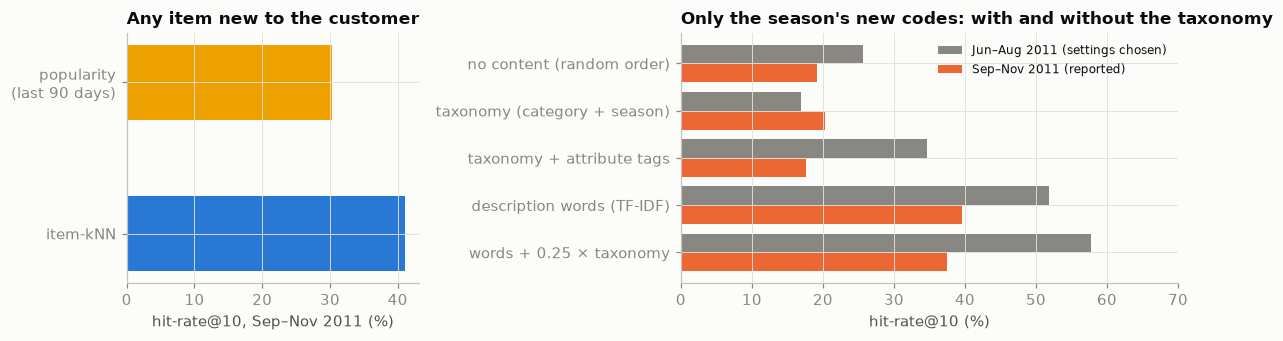

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axes[0]
ax.barh(["item-kNN", "popularity\n(last 90 days)"], [hr_knn * 100, hr_pop * 100], color=[SERIES[0], SERIES[3]], height=0.5)
ax.set_title("Any item new to the customer"); ax.set_xlabel(f"hit-rate@{TOP_N}, Sep–Nov 2011 (%)")
ax = axes[1]
y_ = np.arange(len(ablation))[::-1]
ax.barh(y_ + 0.2, ablation["Jun–Aug 2011 (choose)"] * 100, height=0.4, color=MUTED, label="Jun–Aug 2011 (settings chosen)")
ax.barh(y_ - 0.2, ablation["Sep–Nov 2011 (report)"] * 100, height=0.4, color=SERIES[1], label="Sep–Nov 2011 (reported)")
ax.set_yticks(y_, ablation.index); ax.set_xlabel(f"hit-rate@{TOP_N} (%)"); ax.set_xlim(0, 70); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Only the season's new codes: with and without the taxonomy")
plt.tight_layout()

**The taxonomy covers the range**: 91.1 % of codes, 96.4 % of revenue. SHACL warns on 264 products sold in Jun–Aug 2011 without a category, the to-do list for task S2. The normaliser cuts codes with several wordings only from 646 to 554.

**From the range, item-kNN beats popularity**: 41.1 % of the 2,063 customers who bought something new to them had one in their ten, against 30.2 %. **The launches matter**: 272 codes first sold in Sep–Nov 2011 carried 9.1 % of the quarter's product revenue, bought by 1,488 customers, and item-kNN cannot offer any of them.

**The ablation, honestly read.** On launches the description words reach 39.5 %, close to item-kNN on the range. The taxonomy alone is barely better than random (20.4 % against 19.2 %), and its colour and material tags make it worse (17.7 %). Blended with the words it *helped* in Jun–Aug (57.7 % against 51.9 %, so the weight was chosen) and *hurt* at Christmas (37.4 % against 39.5 %). Sixteen categories are too coarse for recommender context; the taxonomy earns its keep as governed vocabulary. Only 14 launches repeat an old description. Beating 39.5 % is task E1.

**A context pack.** An LLM brief (task S1) may use only facts the system holds: here, for the first customer on the save list. Descriptions are staff-typed free text: data, not instructions.

In [17]:
# ---- the context pack for an account manager's brief (input to task S1: no LLM here, only the facts a brief may use) ----
words_all = normalize(content(R["items"].append(pd.Index(sorted(cold_codes))), "words"))
nw = len(R["items"]); cold_idx = pd.Index(sorted(cold_codes))
def context_pack(u):
    i, row = R["users"].get_loc(u), scored.set_index("customer").loc[u]
    s = np.where(R["seen"][i], -np.inf, S_knn[i])
    new_sc = np.asarray((normalize(R["X"][i] @ words_all[:nw]) @ words_all[nw:].T).todense()).ravel()
    bought = purchase[(purchase.customer.astype(str) == u) & (purchase.ts < TEST_CUTOFF) & (purchase.ts >= TEST_CUTOFF - pd.DateOffset(months=12))]
    cats = bought.assign(cat=bought.stock_code.astype(str).map(taxonomy.category)).groupby("cat").value.sum().nlargest(3)
    return {"customer": u, "as_of": f"{TEST_CUTOFF:%Y-%m-%d}", "country": str(row.country),
            "run_rate_per_quarter_gbp": round(float(row.run_rate_q)), "p_buy_next_quarter": round(float(row.p_lgb), 2),
            "forecast_next_quarter_gbp": round(float(row.rev_lgb_relevelled)), "days_since_last_order": int(row.recency_days),
            "same_quarter_last_year_gbp": round(float(row.rev_same_q_last_year)), "return_share_12m": round(float(row.return_share_365), 3),
            "top_categories_12m": {k: round(v) for k, v in cats.items()},
            "offer_from_range": [taxonomy.description[c] for c in R["items"][np.argsort(-s)[:5]]],
            "offer_new_this_season": [taxonomy.description[c] for c in cold_idx[np.argsort(-new_sc)[:3]]]}
pack = context_pack(chosen.customer.iloc[0])
print(json.dumps(pack, indent=1, ensure_ascii=False))
print(f"{len(json.dumps(pack)):,} characters of JSON per customer → the whole save list ≈ {len(json.dumps(pack)) * K_STAR / 1e3:,.0f} k characters")

{
 "customer": "c4ee73cfe",
 "as_of": "2011-09-01",
 "country": "United Kingdom",
 "run_rate_per_quarter_gbp": 39620,
 "p_buy_next_quarter": 0.36,
 "forecast_next_quarter_gbp": 7021,
 "days_since_last_order": 82,
 "same_quarter_last_year_gbp": 0,
 "return_share_12m": 0.007,
 "top_categories_12m": {
  "storage & boxes": 39916
 },
 "offer_from_range": [
  "PICNIC BASKET WICKER LARGE",
  "RETROSPOT TEA SET CERAMIC 11 PC",
  "LUNCH BAG RED RETROSPOT",
  "SET OF 4 PANTRY JELLY MOULDS",
  "LUNCH BAG CARS BLUE"
 ],
 "offer_new_this_season": [
  "SET 4 PICNIC CUTLERY FONDANT",
  "SET 4 PICNIC CUTLERY BLUEBERRY",
  "SET 4 PICNIC CUTLERY CHERRY"
 ]
}
607 characters of JSON per customer → the whole save list ≈ 62 k characters


## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Six shortcuts, each a better-looking or simpler number and a worse decision, measured naive against honest.

In [18]:
trap_rows = []
# Trap 1 — the duplicated week: keep both copies of 1–9 Dec 2010
dec = lambda d: d[d.is_product & (d.ts >= "2010-12-01") & (d.ts < "2011-01-01")].value.sum()
T_DEC = pd.Timestamp("2010-12-01")
naive_dec = customer_table(T_DEC, customer_lines(raw))
honest_dec = panel[panel.cutoff == T_DEC]
trap_rows += [("1 · duplicated week", "Dec 2010 product sales £", dec(raw), dec(lines)),
              ("1 · duplicated week", "Dec–Feb target revenue of the book £", naive_dec.y_rev.sum(), honest_dec.y_rev.sum())]

# Trap 2 — cancellations dropped as "dirty rows": revenue becomes gross
gross_tab = customer_table(TEST_CUTOFF, customer_lines(lines[~lines.is_cancel]))
net_tab = panel[panel.cutoff == TEST_CUTOFF].set_index("customer")
jar = str(purchase.loc[purchase[purchase.ts < TEST_CUTOFF].quantity.idxmax(), "customer"])      # bought 74,215 jars, cancelled 16 minutes later
rank = lambda tab, c: int((tab.rev_365 > tab.rev_365.get(c, -np.inf)).sum()) + 1
top_gross, top_net = set(gross_tab.rev_365.nlargest(K_CALLS).index), set(net_tab.rev_365.nlargest(K_CALLS).index)
trap_rows += [("2 · cancellations dropped", "Sep–Nov 2011 target revenue of the book £", gross_tab.y_rev.sum(), net_tab.y_rev.sum()),
              ("2 · cancellations dropped", "12-month revenue of the 74,215-jar customer £", gross_tab.rev_365[jar], net_tab.rev_365[jar]),
              ("2 · cancellations dropped", "their rank in the book by 12-month revenue", rank(gross_tab, jar), rank(net_tab, jar)),
              ("2 · cancellations dropped", f"spreadsheet top-{K_CALLS}: customers that change", len(top_gross - top_net), 0)]

# Trap 3 — missing customer IDs filled with one placeholder
filled = lines.assign(customer=lines.customer.cat.add_categories("unknown").fillna("unknown"))
fill_tab = customer_table(TEST_CUTOFF, customer_lines(filled))
trap_rows += [("3 · missing IDs as one customer", "rank of 'unknown' by 12-month revenue", rank(fill_tab, "unknown"), np.nan),
              ("3 · missing IDs as one customer", "'unknown' share of the book's 12-month revenue", fill_tab.rev_365["unknown"] / fill_tab.rev_365.clip(lower=0).sum(), 0.0)]

# Trap 4 — non-product codes (postage, carriage, manual adjustments, discounts) left in customers' revenue and in the recommender
np_tab = customer_table(TEST_CUTOFF, customer_lines(lines, products_only=False))
moved = (np_tab.rev_365.reindex(net_tab.index) - net_tab.rev_365).abs() > 0.10 * net_tab.rev_365.abs().clip(lower=1)
Rn = rec_data(TEST_CUTOFF, products_only=False)
top_naive = np.asarray(Rn["items"], dtype=object)[top_n(knn_scores(Rn["X"]), Rn)]
offers_np = np.isin(top_naive, list(NON_PRODUCT)).any(axis=1)
foreign = net_tab.country.astype(str) != "United Kingdom"
post_buyers = set(lines.loc[(lines.stock_code == "POST") & (lines.ts < TEST_CUTOFF), "customer"].dropna().astype(str))
trap_rows += [("4 · non-product codes kept", "book customers whose 12-month revenue moves > 10 %", int(moved.sum()), 0),
              ("4 · non-product codes kept", "item-kNN lists that offer a non-product code", offers_np.mean(), 0.0)]
print(f"non-UK customers in the book who have paid POSTAGE: {net_tab.index[foreign].isin(post_buyers).mean():.0%} · "
      f"most offered non-product codes in the naive lists: {pd.Series(top_naive[np.isin(top_naive, list(NON_PRODUCT))]).value_counts().head(3).to_dict()}")

# Trap 5 — whole-period customer totals (the CRM's lifetime columns) joined as features
life = cust_lines.groupby("customer").agg(orders_lifetime=("invoice", "nunique"), rev_lifetime=("value", "sum"))
leaky = panel.join(life, on="customer")
tr_l, te_l = split(TEST_CUTOFF, leaky)
clf_l, reg_l = fit_models(tr_l, FEATURES + ["orders_lifetime", "rev_lifetime"])
p_l, r_l = clf_l.predict_proba(te_l[FEATURES + ["orders_lifetime", "rev_lifetime"]])[:, 1], reg_l.predict(te_l[FEATURES + ["orders_lifetime", "rev_lifetime"]])
trap_rows += [("5 · whole-period features", "AUC (buys again), Sep–Nov 2011", roc_auc_score(te_l.y_buy, p_l), res_te.loc["LightGBM", "AUC (buys again)"]),
              ("5 · whole-period features", "MAE £, Sep–Nov 2011", mean_absolute_error(te_l.y_rev, r_l), res_te.loc["LightGBM", "MAE £"])]

# Trap 6 — a random split of customer-quarters instead of a forward one
i_tr, i_te = train_test_split(panel.index, test_size=0.3, random_state=SEED)
clf_r, reg_r = fit_models(panel.loc[i_tr])
te_r = panel.loc[i_te]
trap_rows += [("6 · random split", "AUC (buys again)", roc_auc_score(te_r.y_buy, clf_r.predict_proba(te_r[FEATURES])[:, 1]), res_te.loc["LightGBM", "AUC (buys again)"]),
              ("6 · random split", "forecast ÷ realised", reg_r.predict(te_r[FEATURES]).sum() / te_r.y_rev.sum(), res_te.loc["LightGBM", "forecast ÷ realised"])]
def fmt_trap(measure, v):
    if pd.isna(v):
        return "–"
    if "share" in measure or "lists that" in measure:
        return f"{v:.2%}"
    if "AUC" in measure or "÷" in measure:
        return f"{v:.3f}"
    return f"{v:,.0f}"
traps = pd.DataFrame([(t, m_, fmt_trap(m_, a), fmt_trap(m_, b)) for t, m_, a, b in trap_rows],
                     columns=["trap", "measure", "naive", "honest"]).set_index(["trap", "measure"])
display(traps)

# BG/NBD has no season: its forecast against what happened, quarter by quarter
bg_lvl = pd.Series({f"{T:%b}–{T + pd.DateOffset(months=2):%b %Y}": bg[T].reindex(panel.loc[panel.cutoff == T, "customer"]).rev_bg.sum()
                    / panel.loc[panel.cutoff == T, "y_rev"].sum() for T in bg})
print("BG/NBD forecast ÷ realised by quarter: " + " · ".join(f"{k} {v:.2f}" for k, v in bg_lvl.items()))

non-UK customers in the book who have paid POSTAGE: 72% · most offered non-product codes in the naive lists: {'BANK CHARGES': 1, 'D': 1}


naive     honest
trap                            measure                                                                 
1 · duplicated week             Dec 2010 product sales £                            1,162,687    760,324
                                Dec–Feb target revenue of the book £                1,623,946  1,330,588
2 · cancellations dropped       Sep–Nov 2011 target revenue of the book £           2,694,759  2,619,434
                                12-month revenue of the 74,215-jar customer £          77,184          0
                                their rank in the book by 12-month revenue                  8      4,315
                                spreadsheet top-200: customers that change                  4          0
3 · missing IDs as one customer rank of 'unknown' by 12-month revenue                       1          –
                                'unknown' share of the book's 12-month revenue         14.38%      0.00%
4 · non-product codes kept      book customers whose 12-month revenue moves > 10 %        234          0
                                item-kNN lists that offer a non-product code            0.05%      0.00%
5 · whole-period features       AUC (buys again), Sep–Nov 2011                          0.955      0.778
                                MAE £, Sep–Nov 2011                                       324        412
6 · random split                AUC (buys again)                                        0.794      0.778
                                forecast ÷ realised                                     0.960      0.716

BG/NBD forecast ÷ realised by quarter: Dec–Feb 2011 1.65 · Mar–May 2011 1.34 · Jun–Aug 2011 1.12 · Sep–Nov 2011 0.68


**Trap 1 — the duplicated week.** Load the CSV as it comes and December 2010 sells £1.16M instead of £0.76M (+53 %); the Dec–Feb training target swells by 22 %. `drop_duplicates()` would also delete the 11,812 within-invoice repeats: remove the overlap by provenance.

**Trap 2 — cancellations dropped as "dirty rows".** Revenue becomes gross: the Christmas target rises 2.9 % and four of the spreadsheet's top 200 change. The customer who ordered 74,215 storage jars and cancelled 16 minutes later ranks 8th (£77,184) instead of 4,315th (£0).

**Trap 3 — missing IDs filled with a placeholder.** `fillna("unknown")` creates the book's largest customer: rank 1, 14.4 % of twelve-month revenue, first on every call list. Customers without an ID are a channel: report their share, never score them.

**Trap 4 — non-product codes.** Postage, carriage, discounts and manual adjustments move the twelve-month revenue of 234 customers by more than 10 %; 72 % of non-UK customers have paid postage. The recommender is barely touched (0.05 % of lists offer one): the damage is in revenue features.

**Trap 5 — whole-period customer totals.** Join the CRM's lifetime orders and revenue and AUC jumps from 0.778 to 0.955, MAE falls from £412 to £324: the totals contain the quarter being predicted.

**Trap 6 — the random split, and a model without a season.** Shuffle customer-quarters 70/30 and AUC rises to 0.794; worse, the level looks right (0.96 against 0.72), because every test quarter has its own season in training. BG/NBD has no season: it over-forecasts the quiet quarters (1.65, 1.34, 1.12) and under-forecasts Christmas (0.68).

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the range turns over, the level swings, the inputs stay quiet

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi_shares`; E3 turns re-levelling into a monitored step.*

Freeze the models and the recommender's catalogue and run them forward on Task 02's two clocks. **Now**: country mix, basket size, sales on codes the recommender never saw. **Later**: the forecast against each quarter, three months on.

codes under 12 months old: 26%–43% of monthly revenue · under 90 days: 6%–20%, highest in Jun 2011 20%, May 2011 18%, Jan 2011 18%
unknown to the recommender, mean of the last 4 whole weeks to 27 Nov 2011: catalogue frozen 01 Jun 20% · catalogue frozen 01 Sep 9%


,PSI country mix,PSI basket size,UK share of revenue
quarter,,,
Dec 09,0.006,0.002,0.850
Mar 10,0.002,0.003,0.866
Jun 10,0.004,0.004,0.864
Sep 10,0.002,0.003,0.859
Dec 10,0.014,0.005,0.854
Mar 11,0.015,0.003,0.851
Jun 11,0.021,0.002,0.819
Sep 11,0.009,0.010,0.856


,AUC frozen,AUC retrained,forecast ÷ realised · frozen,forecast ÷ realised · retrained,forecast ÷ realised · BG/NBD
quarter,,,,,
Dec–Feb 11,0.78,0.78,2.61,2.61,1.65
Mar–May 11,0.76,0.77,2.17,1.09,1.34
Jun–Aug 11,0.79,0.81,1.60,0.73,1.12
Sep–Nov 11,0.76,0.78,1.22,0.72,0.68


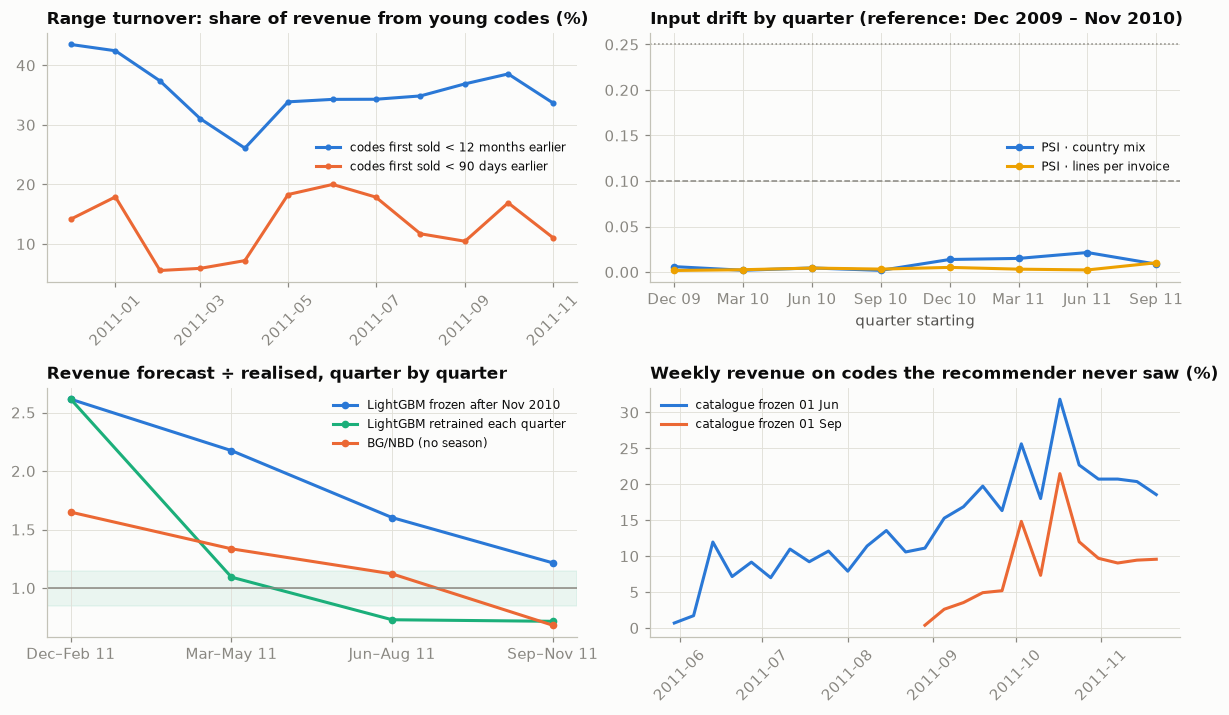

In [19]:
def psi_shares(ref, cur):
    ref, cur = ref.align(cur, fill_value=0)
    ref, cur = ref / ref.sum() + 1e-4, cur / cur.sum() + 1e-4
    return float(np.sum((cur - ref) * np.log(cur / ref)))

pm = purchase.assign(month=purchase.ts.dt.to_period("M"), code=purchase.stock_code.astype(str))
pm["age_days"] = (pm.ts - pm.code.map(first_sale)).dt.days
monthly = pm.groupby("month").apply(lambda d: pd.Series({
    "new in 12 months": d.value[d.age_days < 365].sum() / d.value.sum(),
    "new in 90 days": d.value[d.age_days < 90].sum() / d.value.sum()}), include_groups=False)
monthly.loc[monthly.index < pd.Period("2010-12", "M"), "new in 12 months"] = np.nan       # needs a full year of history
monthly.loc[monthly.index < pd.Period("2010-12", "M"), "new in 90 days"] = np.nan          # same rule: before that, "new" may only mean "new to the extract"
monthly = monthly[monthly.index < pd.Period("2011-12", "M")]                            # Dec 2011 holds only 9 days

pq = pm.assign(quarter=pm.ts.dt.to_period("Q-NOV"))
pq = pq[pq.quarter < pd.Period("2012Q1", "Q-NOV")]
REF_Q = pq.quarter.unique()[:4]                                                        # Dec 2009 – Nov 2010 as the reference year
cgrp = pq.country.astype(str).where(pq.country.astype(str).isin(TOP_COUNTRIES), "Other")
ref_c = pq[pq.quarter.isin(REF_Q)].groupby(cgrp).value.sum()
basket = pq.groupby(["quarter", "invoice"]).size().rename("lines").reset_index()
bins = [0, 5, 10, 20, 40, 80, 10_000]
ref_b = pd.cut(basket[basket.quarter.isin(REF_Q)].lines, bins).value_counts()
drift = pd.DataFrame({
    "PSI country mix": {q: psi_shares(ref_c, pq[pq.quarter == q].groupby(cgrp).value.sum()) for q in pq.quarter.unique()},
    "PSI basket size": {q: psi_shares(ref_b, pd.cut(basket[basket.quarter == q].lines, bins).value_counts()) for q in pq.quarter.unique()},
    "UK share of revenue": pq.groupby("quarter").apply(lambda d: d.value[d.country == "United Kingdom"].sum() / d.value.sum(), include_groups=False)})

# The models, frozen after Sep–Nov 2010 against retrained every quarter
frozen_tr = panel[panel.cutoff + pd.DateOffset(months=HORIZON_MONTHS) <= pd.Timestamp("2010-12-01")]
clf_f, reg_f = fit_models(frozen_tr)
life_rows = []
for T in CUTOFFS[CUTOFFS >= pd.Timestamp("2010-12-01")]:
    tr_, te_ = split(T)
    clf_t, reg_t = fit_models(tr_)
    life_rows.append({"quarter": f"{T:%b}–{T + pd.DateOffset(months=2):%b %y}",
                      "AUC frozen": roc_auc_score(te_.y_buy, clf_f.predict_proba(te_[FEATURES])[:, 1]),
                      "AUC retrained": roc_auc_score(te_.y_buy, clf_t.predict_proba(te_[FEATURES])[:, 1]),
                      "forecast ÷ realised · frozen": reg_f.predict(te_[FEATURES]).sum() / te_.y_rev.sum(),
                      "forecast ÷ realised · retrained": reg_t.predict(te_[FEATURES]).sum() / te_.y_rev.sum(),
                      "forecast ÷ realised · BG/NBD": bg_lvl.iloc[len(life_rows)]})
life_tab = pd.DataFrame(life_rows).set_index("quarter")

# The recommender's catalogue, frozen at each cut-off: what share of later purchases does it not know?
weeks = pm[(pm.ts >= VALID_CUTOFF) & (pm.ts < pd.Timestamp("2011-11-28")) & pm.customer.notna()].assign(week=lambda d: d.ts.dt.to_period("W"))  # whole weeks
cover = {}
for T in [VALID_CUTOFF, TEST_CUTOFF]:
    known_items = set(pm.loc[(pm.ts < T) & (pm.ts >= T - pd.DateOffset(months=ACTIVE_MONTHS)), "code"])
    w = weeks[weeks.ts >= T]
    cover[f"catalogue frozen {T:%d %b}"] = w.groupby("week").apply(lambda d: d.value[~d.code.isin(known_items)].sum() / d.value.sum(), include_groups=False)
cover = pd.DataFrame(cover)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
ax = axes[0, 0]
ax.plot(monthly.index.to_timestamp(), monthly["new in 12 months"] * 100, "-o", ms=3, lw=2, color=SERIES[0], label="codes first sold < 12 months earlier")
ax.plot(monthly.index.to_timestamp(), monthly["new in 90 days"] * 100, "-o", ms=3, lw=2, color=SERIES[1], label="codes first sold < 90 days earlier")
ax.set_title("Range turnover: share of revenue from young codes (%)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axes[0, 1]
lbl_q = [f"{q.start_time:%b %y}" for q in drift.index]
ax.plot(lbl_q, drift["PSI country mix"], "-o", ms=4, lw=2, color=SERIES[0], label="PSI · country mix")
ax.plot(lbl_q, drift["PSI basket size"], "-o", ms=4, lw=2, color=SERIES[3], label="PSI · lines per invoice")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_title("Input drift by quarter (reference: Dec 2009 – Nov 2010)"); ax.legend(fontsize=8); ax.set_xlabel("quarter starting")
ax = axes[1, 0]
ax.plot(life_tab.index, life_tab["forecast ÷ realised · frozen"], "-o", ms=4, lw=2, color=SERIES[0], label="LightGBM frozen after Nov 2010")
ax.plot(life_tab.index, life_tab["forecast ÷ realised · retrained"], "-o", ms=4, lw=2, color=SERIES[2], label="LightGBM retrained each quarter")
ax.plot(life_tab.index, life_tab["forecast ÷ realised · BG/NBD"], "-o", ms=4, lw=2, color=SERIES[1], label="BG/NBD (no season)")
ax.axhline(1, color=MUTED, lw=1); ax.axhspan(0.85, 1.15, color=SERIES[2], alpha=0.08)
ax.set_title("Revenue forecast ÷ realised, quarter by quarter"); ax.legend(fontsize=8)
ax = axes[1, 1]
for (name, s), col in zip(cover.items(), [SERIES[0], SERIES[1]]):
    ax.plot(s.index.to_timestamp(), s.values * 100, lw=2, color=col, label=name)
ax.set_title("Weekly revenue on codes the recommender never saw (%)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
n90 = monthly["new in 90 days"].dropna()
print(f"codes under 12 months old: {monthly['new in 12 months'].min():.0%}–{monthly['new in 12 months'].max():.0%} of monthly revenue · "
      f"under 90 days: {n90.min():.0%}–{n90.max():.0%}, highest in " + ", ".join(f"{m:%b %Y} {v:.0%}" for m, v in n90.nlargest(3).items()))
print("unknown to the recommender, mean of the last 4 whole weeks to 27 Nov 2011: "
      + " · ".join(f"{c} {v:.0%}" for c, v in cover.tail(4).mean().items()))
display(drift.assign(quarter=lbl_q).set_index("quarter").style.format("{:.3f}"))
display(life_tab.style.format("{:.2f}"))

**The inputs stay quiet.** PSI on country mix stays at or below 0.021, on basket size at or below 0.010; the UK takes 82–87 % of revenue every quarter. The card's "changing country mix" is not in this data.

**The range turns over.** Codes first sold within the previous twelve months carry 26–43 % of each month's revenue, codes under 90 days old 6–20 %. A catalogue frozen on 1 June misses the codes behind 20 % of revenue in the last four weeks of November; frozen on 1 September, 9 %. 

**The level swings, the ranking does not.** AUC stays at 0.76–0.81, frozen or retrained. Frozen after November 2010, the model forecasts 2.61, 2.17, 1.60 and 1.22 times what each quarter bought; retrained, 1.09, 0.73 and 0.72 after its first. For the monitoring plan (task C5): *forecast ÷ realised* per quarter is the primary signal, alerting outside 0.85–1.15 and re-levelling before retraining; *catalogue coverage* is the recommender's weekly early warning; input PSI is only a health check here.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/customer_value/` (`features`, `bgnbd`, `train`, `recommend`, `batch`); quarterly call-list batch (4,324 customers); `GET /recommend/{customer}` from nightly item-kNN (3,708 items) plus content for launches. |
| Monitoring (S04) | Forecast ÷ realised per quarter (alert outside 0.85–1.15; frozen model 2.61 → 1.22); weekly share of revenue on codes unknown to the recommender (20 % by November on a June catalogue); PSI on country mix (≤ 0.021) and basket size (≤ 0.010) as health checks; monthly hit-rate@10; RED metrics. |
| CI/CD gate (S05) | Frozen Sep–Nov 2011 holdout, SHA-256 `2dc34804a071ba91…`. The model must beat the legacy baselines on it: AUC above the spreadsheet's 0.746 (0.778; lead +0.032 [0.023, 0.040]), re-levelled level in 0.85–1.15 (0.98), hit-rate@10 above popularity's 0.302 on the range (0.411) and random's 0.192 on launches (0.395). Absolute bars are the business's to set (task C3). Plus as-of, net-revenue and non-product tests. |
| MLflow tracking and registry (S06) | Cut-offs, book window, features, model family (spreadsheet, RFM, BG/NBD, LightGBM), re-levelling factor (×1.37), kNN neighbours, blend weight; fingerprints; `champion` and `challenger` aliases. |
| Offline / online training and serving | Offline: retrain and re-level each quarter as labels mature (three months' delay). Online: recommendations during the call; launches scored by content on entry. |
| Data and model drift | Range: codes under a year old carry 26–43 % of monthly revenue. Level: forecast ÷ realised 0.68–2.61 across quarters. Season: buy rate 33–37 % off-season, 50 % before Christmas 2011. Country mix: none (PSI ≤ 0.021). |
| Knowledge base and context (S07–S09) | Rule-based taxonomy (16 categories, season and attribute tags) as SKOS, 14,737 triples; SHACL: 0 violations, 264 warnings. Ablation on launches: words 39.5 %, words + taxonomy 37.4 %, taxonomy alone 20.4 %, random 19.2 %. |
| GenAI and context engineering (S10–S11) | Brief from a ≈ 600-character context pack; golden set of exact numbers; descriptions as untrusted text; LLM normalisation of 554 multi-wording and 264 unclassified codes. |
| Governance | Real data; Kaggle CC0, UCI CC BY 4.0; customer numbers as keyed hashes (key in a vault), staff names redacted; customers without an ID never scored; a person makes the call; the uplift is unmeasured and said so. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Remove the overlap by provenance, net cancellations, keep unidentified customers and non-product codes out of features; `tests/test_features.py` fails if a feature reads a row on or after the cut-off. Decide, with evidence, about the 11,812 repeated lines.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `CALLS_PER_QUARTER` (50–400), `CALL_COST_GBP`, `GROSS_MARGIN` and `WIN_BACK_RATE`; compare grow, save and mixed lists; write the ADR that commits to measuring the win-back rate with a randomised hold-out, sized to detect 10 %.
- **C4 — Package, container, gate.** `src/customer_value/` with the batch and `GET /recommend/{customer}` as entry points, a slim container, and `make ci` gating ranking, level and hit-rate@10 against the legacy baselines on the Sep–Nov 2011 holdout, refusing if its SHA-256 changes (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs per model family and recommender, `champion` and `challenger` aliases, a model card (the quirks, the unmeasured uplift, the level problem), and a monitoring plan with forecast ÷ realised, catalogue coverage and the re-levelling and retraining triggers (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** Grow the taxonomy from competency questions (*which launches continue a line this customer buys?*), validate it with SHACL in CI, version it, and measure hit-rate@10 on launches with and without it, chosen on Jun–Aug and reported on Sep–Nov: beat 39.5 % (Sessions 07–09).
- **E2 — Governance and fairness.** Who is never called or offered anything new? Measure coverage by country, size and tenure; state the GDPR position for sole traders and argue the AI Act position.
- **E3 — Watch the level.** Every model under-forecasts the level. Make re-levelling a monitored, logged step: track forecast ÷ actual by quarter, set the alert threshold, and log the factor in MLflow (no new model).
- **E4 — First orders.** 273–990 buyers a quarter are new to the book and the model cannot score them. Decide the business rule for them (welcome call, offer or nothing), size it against the 200-call capacity, and argue it in an ADR with numbers.

### Stretch

- **S1 — The account-manager brief.** From the context pack and taxonomy only: versioned prompt, structured output, a golden set of 30 customers whose numbers must be reproduced exactly, factuality and tone checks, injection tests through descriptions, cost per brief (Sessions 10–11).
- **S2 — LLM-assisted description normalisation.** Normalise the 554 multi-wording codes and classify the 264 unclassified ones against a hand-checked golden set; rerun the ablation.
- **S3 — Online and streaming serving.** `GET /recommend/{customer}` within a latency budget; launches scored from catalogue events, coverage from the order stream; cost per 1,000 calls.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` and the pseudonym key not in Git
- [ ] `README.md` states the window, cut-offs, account-book rule, the duplicated week and the data source (Kaggle CC0; cite UCI, CC BY 4.0)
- [ ] Forward evaluation only; traps removed; as-of, net-revenue and non-product tests in the suite
- [ ] Call-list operating point in an ADR, including how the win-back rate will be measured
- [ ] CI gate on the fingerprinted holdout; registered model, model card, monitoring plan
- [ ] Taxonomy as a versioned KB with SHACL shapes and the cold-start ablation
- [ ] One-page recommendation for the head of sales
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scipy`, `scikit-learn`, `lightgbm`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Chen, D. (2019). *Online Retail II* [dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D
- Fader, P. S., Hardie, B. G. S., Lee, K. L. (2005). "Counting your customers" the easy way: an alternative to the Pareto/NBD model. *Marketing Science*, 24(2), 275–284.
- Fader, P. S., Hardie, B. G. S., Lee, K. L. (2005). RFM and CLV: using iso-value curves for customer base analysis. *Journal of Marketing Research*, 42(4), 415–430.
- Sarwar, B., Karypis, G., Konstan, J., Riedl, J. (2001). Item-based collaborative filtering recommendation algorithms. *WWW '01*.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (leakage), Ch. 8 (distribution shifts and monitoring).
- W3C (2009). *SKOS Reference*; W3C (2017). *Shapes Constraint Language (SHACL)*.

In [20]:
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · scipy {scipy.__version__} · "
      f"numpy {np.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · scipy 1.18.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 83s
